In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('../notebook/data/Housing 3.csv')

In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.shape

(545, 13)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [7]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.corr(numeric_only=True)['price']

price        1.000000
area         0.535997
bedrooms     0.366494
bathrooms    0.517545
stories      0.420712
parking      0.384394
Name: price, dtype: float64

# Univariate Analysis


In [14]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [15]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

In [20]:
num_cols=['price','area']
cat_cols=df.columns.drop(num_cols)

In [23]:
print(num_cols,'\n'*3,cat_cols)

['price', 'area'] 


 Index(['bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
       'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus'],
      dtype='str')


## numerical univariate

In [24]:
def analyze_numerical(df, column):
    """
    Comprehensive analysis of a numerical column
    """
    print(f"\n{'='*50}")
    print(f"Analysis of: {column}")
    print(f"{'='*50}")

    # Basic statistics
    print("\nBasic Statistics:")
    print(df[column].describe())

    # Additional statistics
    print(f"\nMean: {df[column].mean():.2f}")
    print(f"Median: {df[column].median():.2f}")
    print(f"Mode: {df[column].mode().values}")
    print(f"Std Dev: {df[column].std():.2f}")
    print(f"Variance: {df[column].var():.2f}")
    print(f"Skewness: {df[column].skew():.2f}")
    print(f"Kurtosis: {df[column].kurtosis():.2f}")

    # Outliers (IQR method)
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    print(f"\nOutliers (IQR method): {len(outliers)}")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Histogram
    axes[0, 0].hist(df[column].dropna(), bins=30, edgecolor='black')
    axes[0, 0].set_title(f'Histogram of {column}')
    axes[0, 0].set_xlabel(column)
    axes[0, 0].set_ylabel('Frequency')

    # Box plot
    axes[0, 1].boxplot(df[column].dropna())
    axes[0, 1].set_title(f'Box Plot of {column}')
    axes[0, 1].set_ylabel(column)

    # KDE plot
    axes[1, 0].hist(df[column].dropna(), bins=30, density=True, alpha=0.7, label='Histogram')
    df[column].dropna().plot(kind='kde', ax=axes[1, 0], label='KDE')
    axes[1, 0].set_title(f'Distribution of {column}')
    axes[1, 0].set_xlabel(column)
    axes[1, 0].legend()

    # Q-Q plot (check normality)
    from scipy import stats
    stats.probplot(df[column].dropna(), dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title(f'Q-Q Plot of {column}')

    plt.tight_layout()
    plt.show()



Analysis of: price

Basic Statistics:
count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64

Mean: 4766729.25
Median: 4340000.00
Mode: [3500000 4200000]
Std Dev: 1870439.62
Variance: 3498544355820.57
Skewness: 1.21
Kurtosis: 1.96

Outliers (IQR method): 15


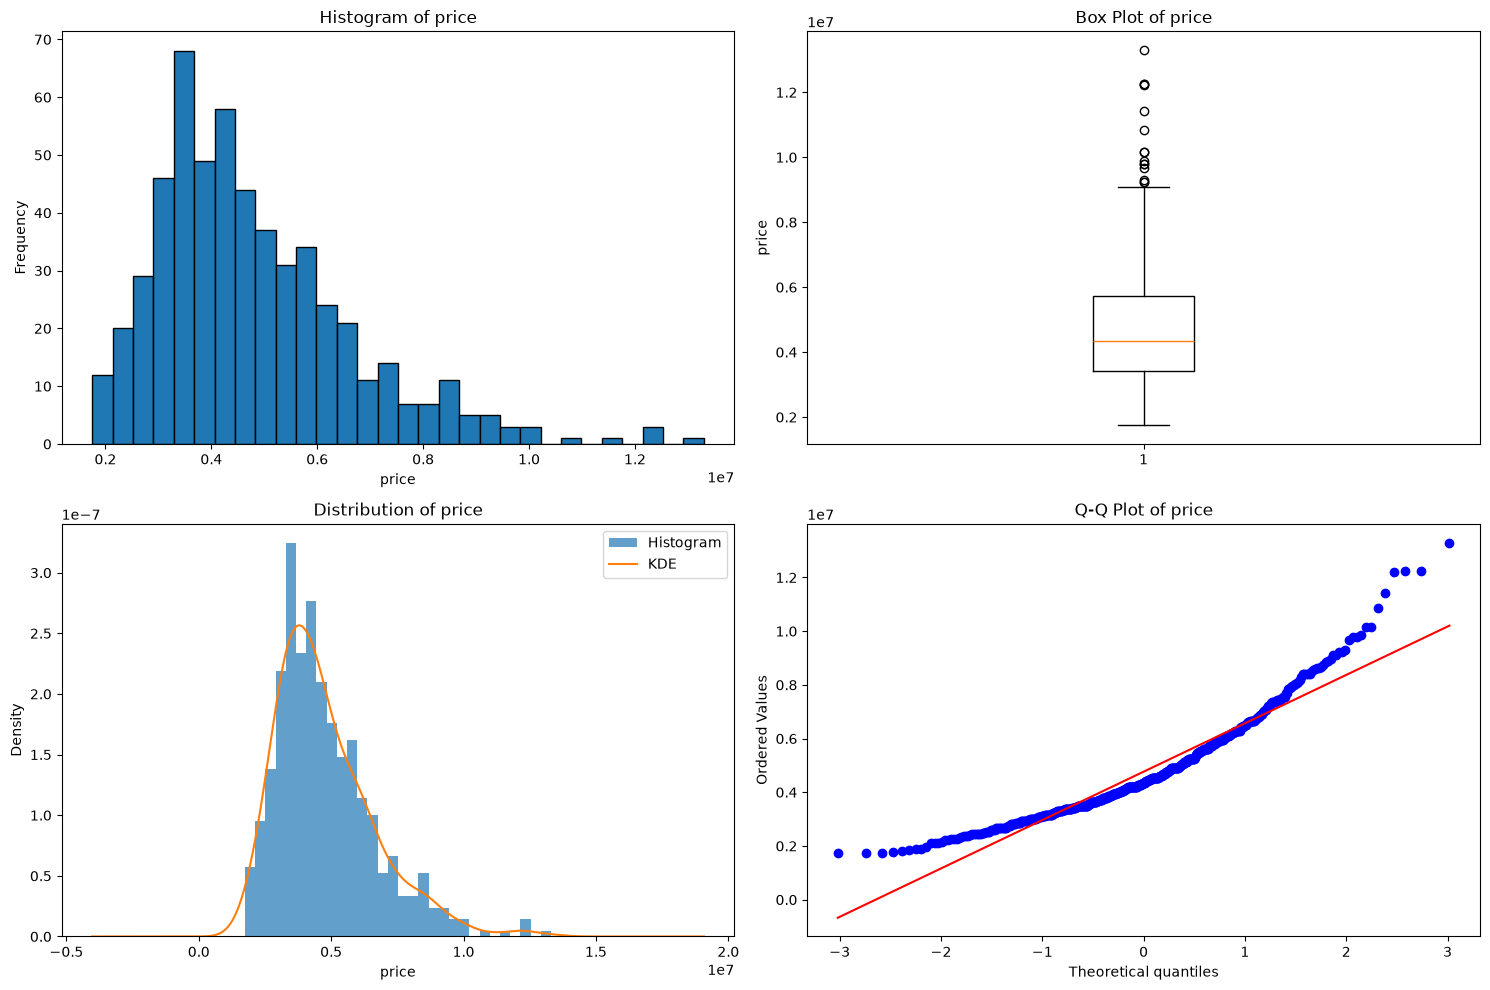


Analysis of: area

Basic Statistics:
count      545.000000
mean      5150.541284
std       2170.141023
min       1650.000000
25%       3600.000000
50%       4600.000000
75%       6360.000000
max      16200.000000
Name: area, dtype: float64

Mean: 5150.54
Median: 4600.00
Mode: [6000]
Std Dev: 2170.14
Variance: 4709512.06
Skewness: 1.32
Kurtosis: 2.75

Outliers (IQR method): 12


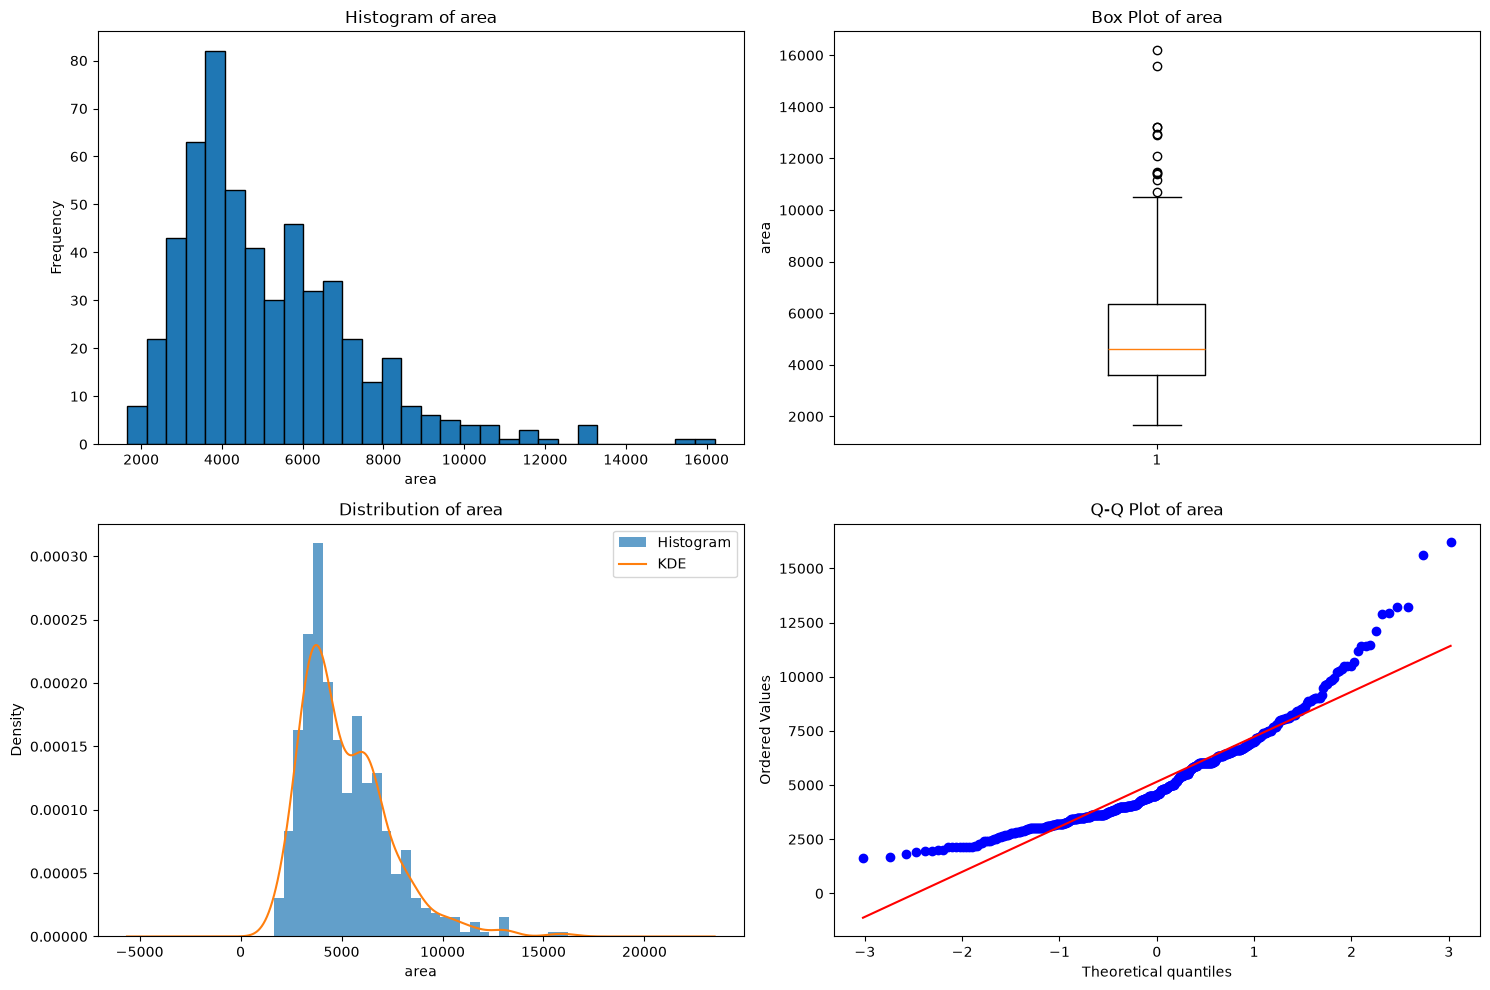

In [25]:
for column in num_cols:
    analyze_numerical(df,column)

## categorical univariate

In [26]:
def analyze_categorical(df, column):
    """
    Comprehensive analysis of a categorical column
    """
    print(f"\n{'='*50}")
    print(f"Analysis of: {column}")
    print(f"{'='*50}")

    # Value counts
    value_counts = df[column].value_counts()
    print("\nValue Counts:")
    print(value_counts)

    # Percentages
    print("\nPercentages:")
    print(df[column].value_counts(normalize=True) * 100)

    # Unique values
    print(f"\nNumber of unique values: {df[column].nunique()}")
    print(f"Unique values: {df[column].unique()}")

    # Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Bar plot
    value_counts.plot(kind='bar', ax=axes[0])
    axes[0].set_title(f'Bar Plot of {column}')
    axes[0].set_xlabel(column)
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)

    # Pie chart
    value_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%')
    axes[1].set_title(f'Pie Chart of {column}')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()



Analysis of: bedrooms

Value Counts:
bedrooms
3    300
2    136
4     95
5     10
6      2
1      2
Name: count, dtype: int64

Percentages:
bedrooms
3    55.045872
2    24.954128
4    17.431193
5     1.834862
6     0.366972
1     0.366972
Name: proportion, dtype: float64

Number of unique values: 6
Unique values: [4 3 5 2 6 1]


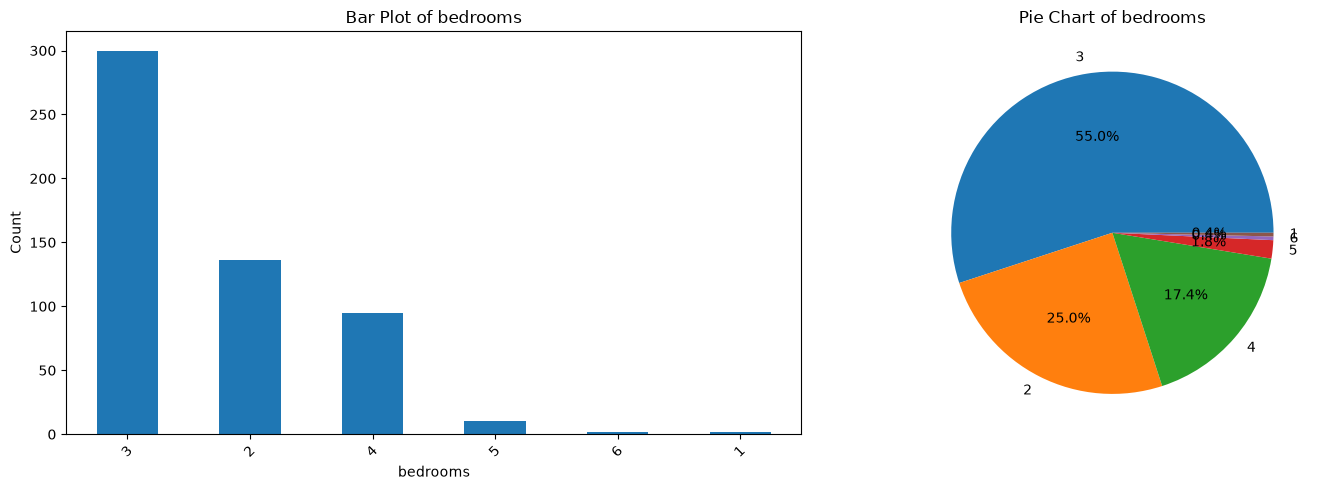


Analysis of: bathrooms

Value Counts:
bathrooms
1    401
2    133
3     10
4      1
Name: count, dtype: int64

Percentages:
bathrooms
1    73.577982
2    24.403670
3     1.834862
4     0.183486
Name: proportion, dtype: float64

Number of unique values: 4
Unique values: [2 4 1 3]


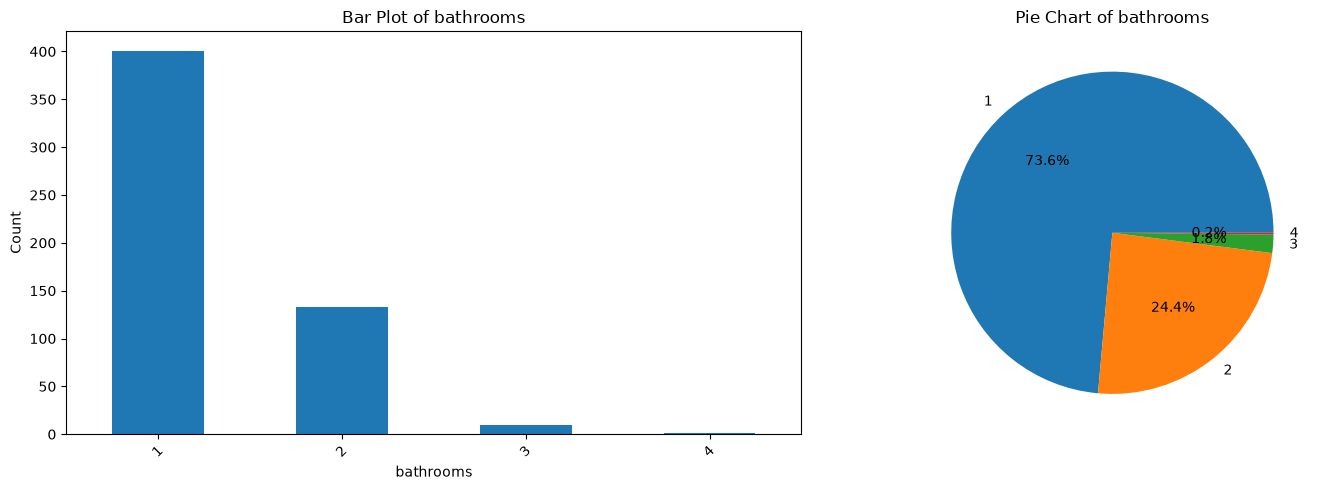


Analysis of: stories

Value Counts:
stories
2    238
1    227
4     41
3     39
Name: count, dtype: int64

Percentages:
stories
2    43.669725
1    41.651376
4     7.522936
3     7.155963
Name: proportion, dtype: float64

Number of unique values: 4
Unique values: [3 4 2 1]


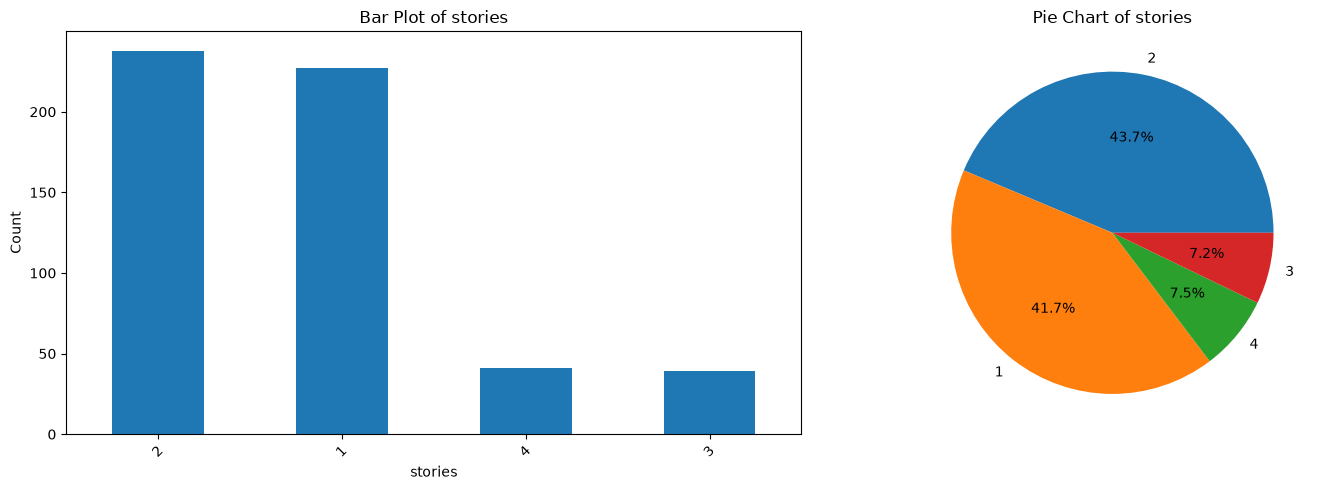


Analysis of: mainroad

Value Counts:
mainroad
yes    468
no      77
Name: count, dtype: int64

Percentages:
mainroad
yes    85.87156
no     14.12844
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str


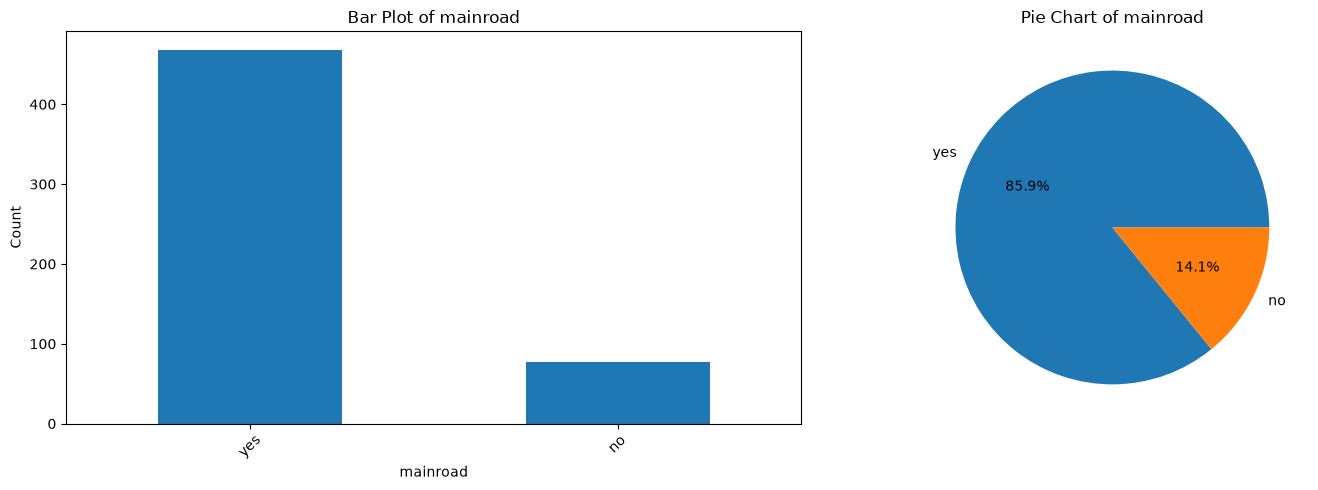


Analysis of: guestroom

Value Counts:
guestroom
no     448
yes     97
Name: count, dtype: int64

Percentages:
guestroom
no     82.201835
yes    17.798165
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str


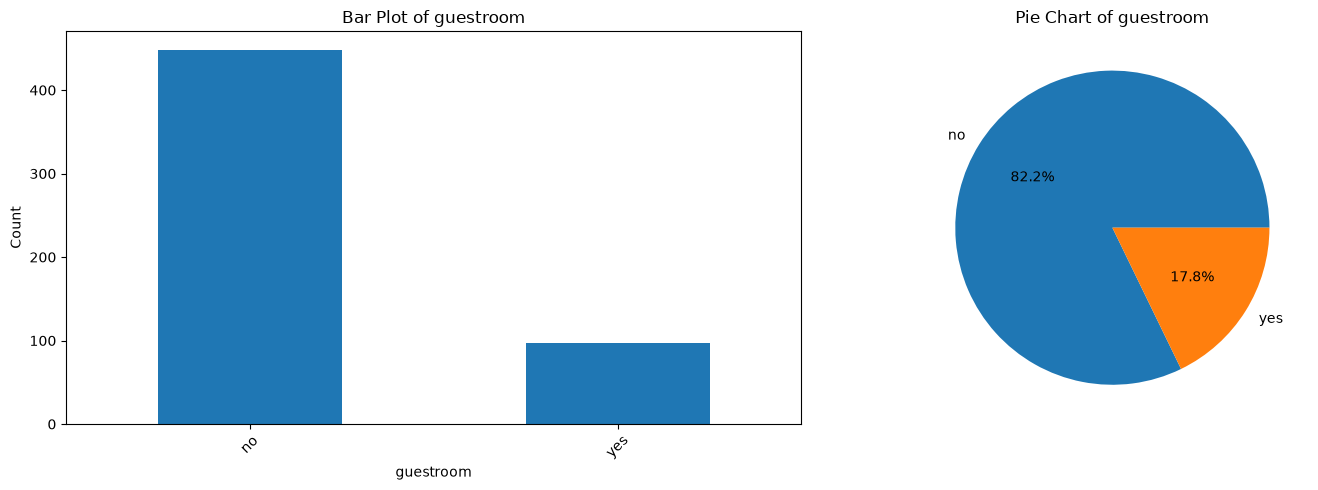


Analysis of: basement

Value Counts:
basement
no     354
yes    191
Name: count, dtype: int64

Percentages:
basement
no     64.954128
yes    35.045872
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str


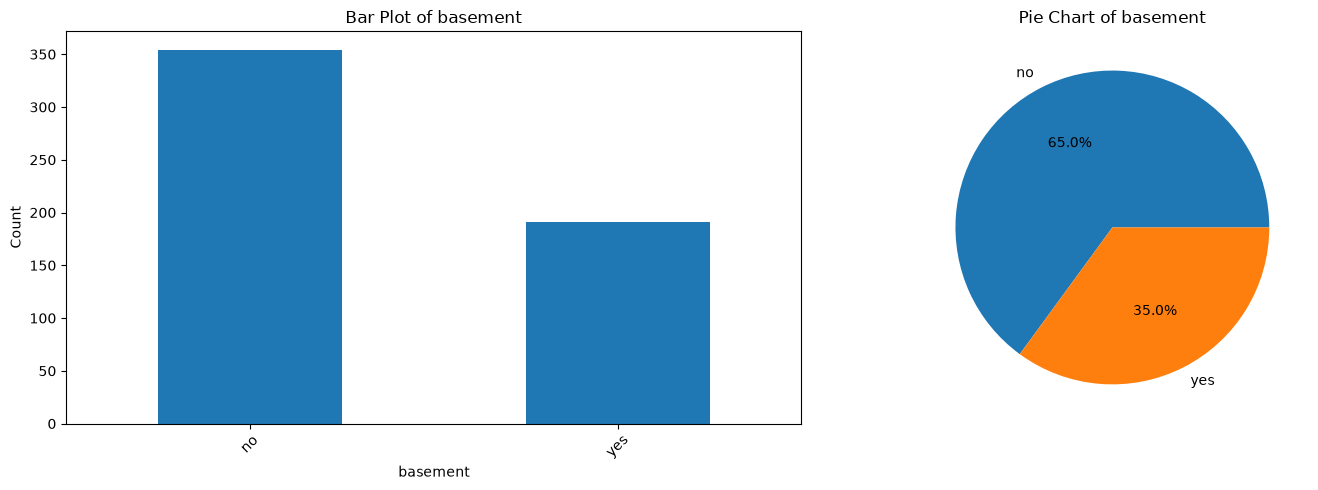


Analysis of: hotwaterheating

Value Counts:
hotwaterheating
no     520
yes     25
Name: count, dtype: int64

Percentages:
hotwaterheating
no     95.412844
yes     4.587156
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str


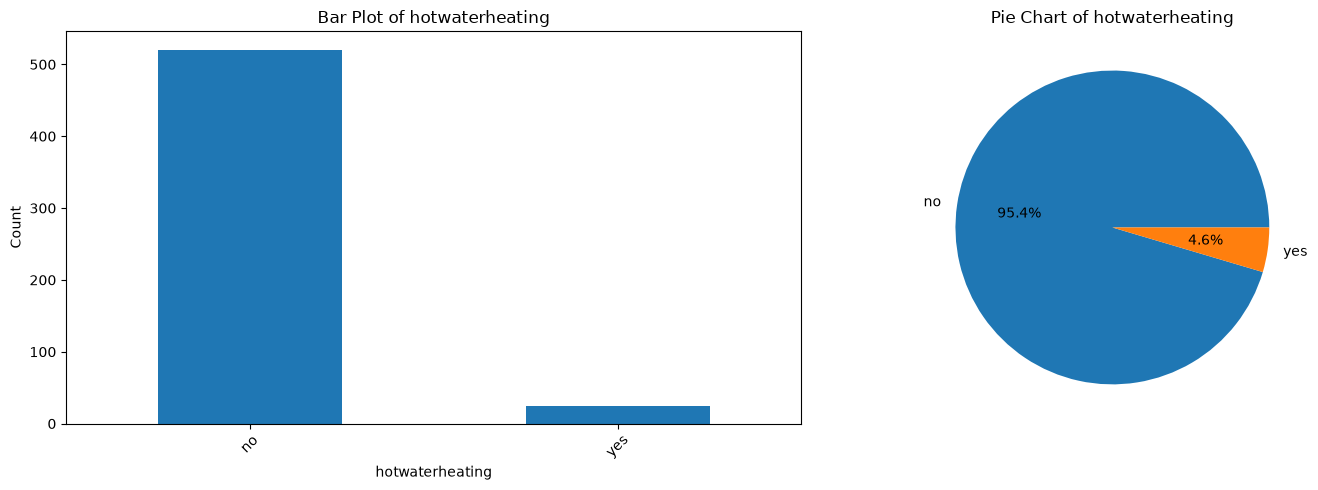


Analysis of: airconditioning

Value Counts:
airconditioning
no     373
yes    172
Name: count, dtype: int64

Percentages:
airconditioning
no     68.440367
yes    31.559633
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str


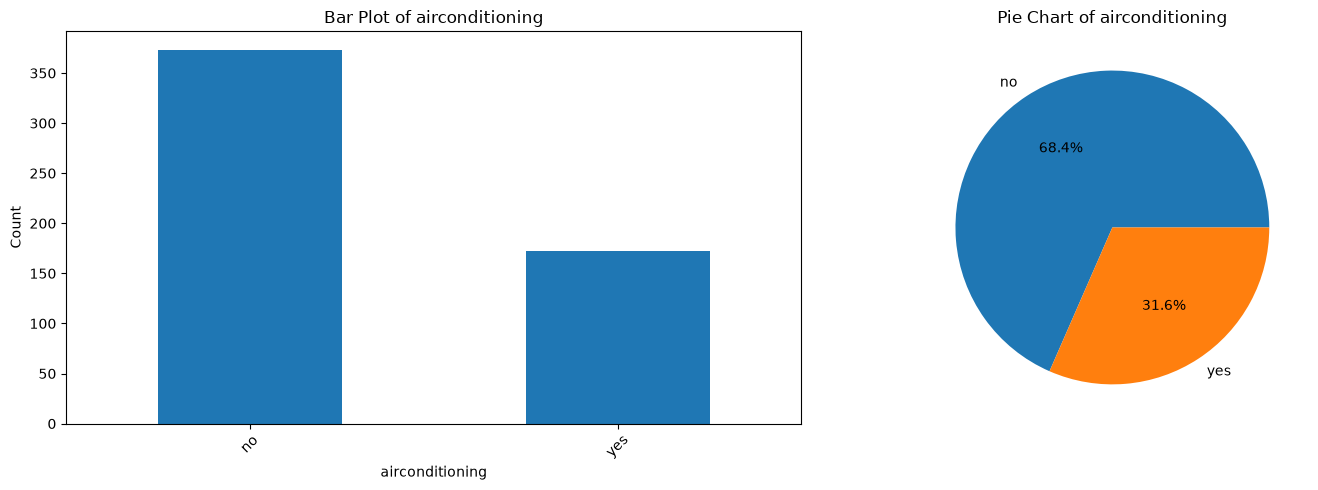


Analysis of: parking

Value Counts:
parking
0    299
1    126
2    108
3     12
Name: count, dtype: int64

Percentages:
parking
0    54.862385
1    23.119266
2    19.816514
3     2.201835
Name: proportion, dtype: float64

Number of unique values: 4
Unique values: [2 3 0 1]


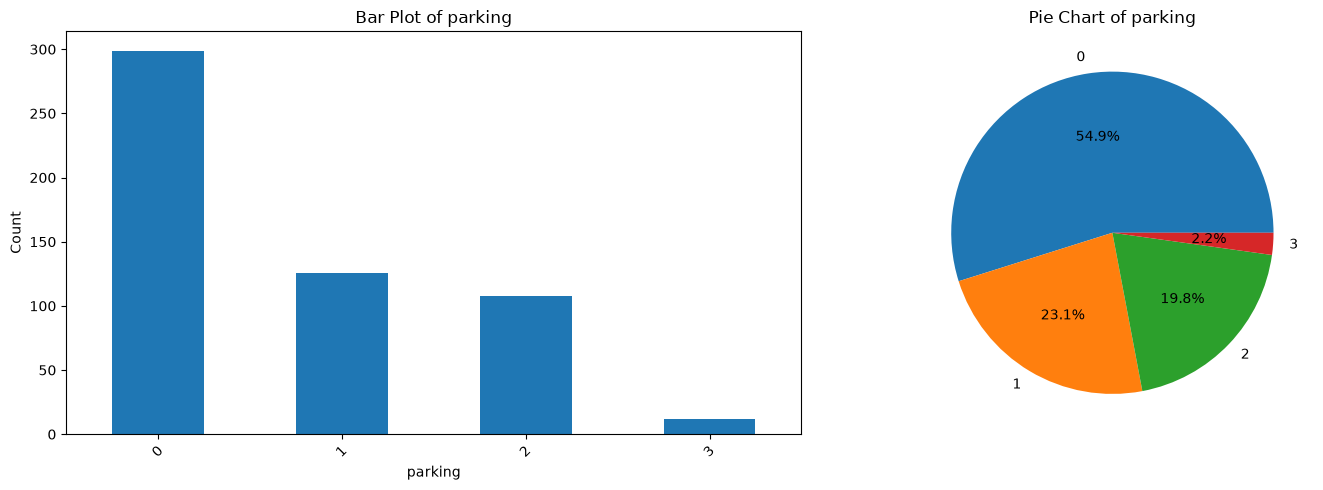


Analysis of: prefarea

Value Counts:
prefarea
no     417
yes    128
Name: count, dtype: int64

Percentages:
prefarea
no     76.513761
yes    23.486239
Name: proportion, dtype: float64

Number of unique values: 2
Unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str


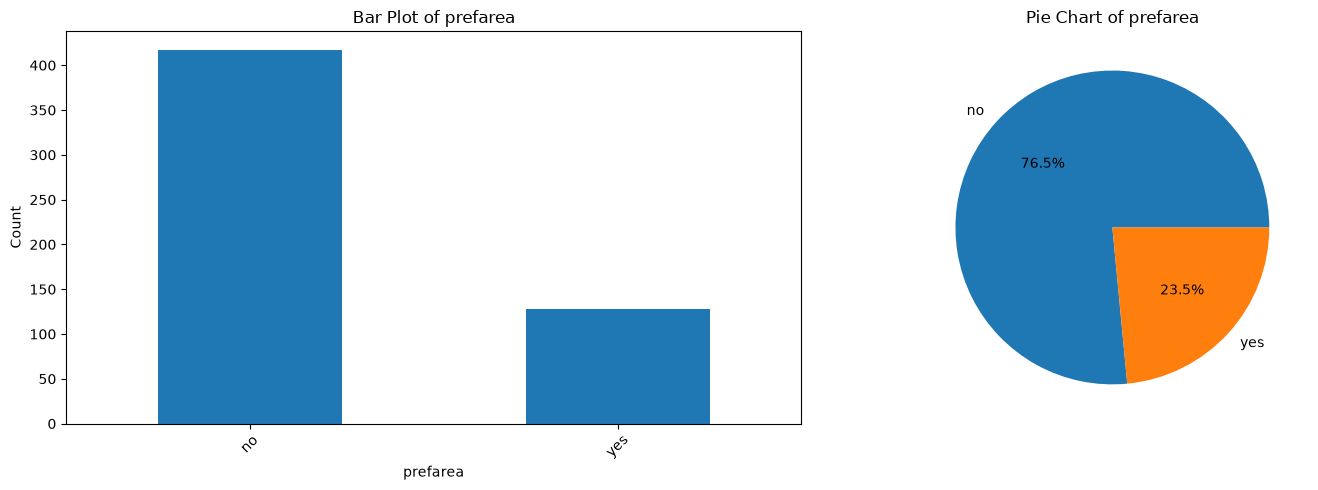


Analysis of: furnishingstatus

Value Counts:
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64

Percentages:
furnishingstatus
semi-furnished    41.651376
unfurnished       32.660550
furnished         25.688073
Name: proportion, dtype: float64

Number of unique values: 3
Unique values: <StringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str


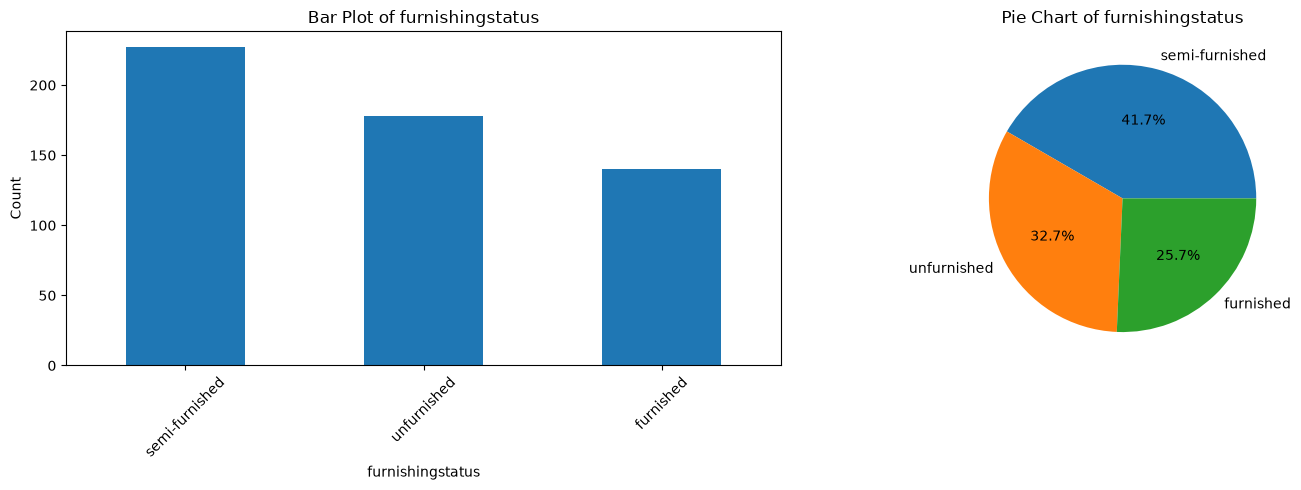

In [27]:
for column in cat_cols:
    analyze_categorical(df,column)

# Bi Variate Analysis

## numerical vs numerical

In [30]:
def analyze_numerical_pair(df, col1, col2):
    """
    Analyze relationship between two numerical variables
    """
    # Correlation
    correlation = df[col1].corr(df[col2])
    print(f"\nCorrelation between {col1} and {col2}: {correlation:.3f}")
    
    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Scatter plot
    axes[0, 0].scatter(df[col1], df[col2], alpha=0.5)
    axes[0, 0].set_xlabel(col1)
    axes[0, 0].set_ylabel(col2)
    axes[0, 0].set_title(f'Scatter Plot: {col1} vs {col2}')
    
    # Add regression line
    z = np.polyfit(df[col1].dropna(), df[col2].dropna(), 1)
    p = np.poly1d(z)
    axes[0, 0].plot(df[col1], p(df[col1]), "r--", alpha=0.5)
    
    # Hexbin plot (for large datasets)
    axes[0, 1].hexbin(df[col1], df[col2], gridsize=20, cmap='Blues')
    axes[0, 1].set_xlabel(col1)
    axes[0, 1].set_ylabel(col2)
    axes[0, 1].set_title(f'Hexbin Plot: {col1} vs {col2}')
    
    # Joint plot (using seaborn)
    sns.jointplot(data=df, x=col1, y=col2, kind='scatter', ax=axes[1, 0])
    
    # 2D Histogram
    axes[1, 1].hist2d(df[col1], df[col2], bins=20, cmap='Blues')
    axes[1, 1].set_xlabel(col1)
    axes[1, 1].set_ylabel(col2)
    axes[1, 1].set_title(f'2D Histogram: {col1} vs {col2}')
    
    plt.tight_layout()
    plt.show()



Correlation between price and area: 0.536


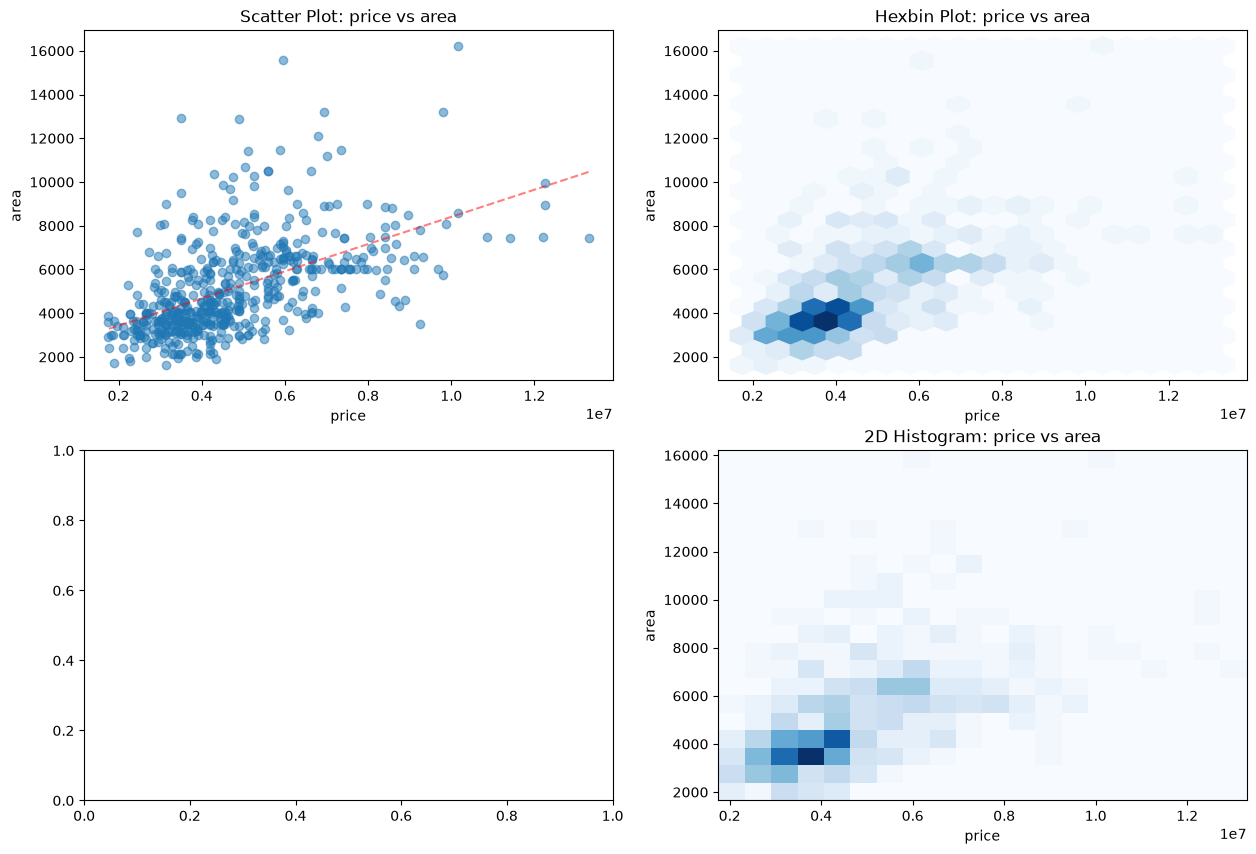

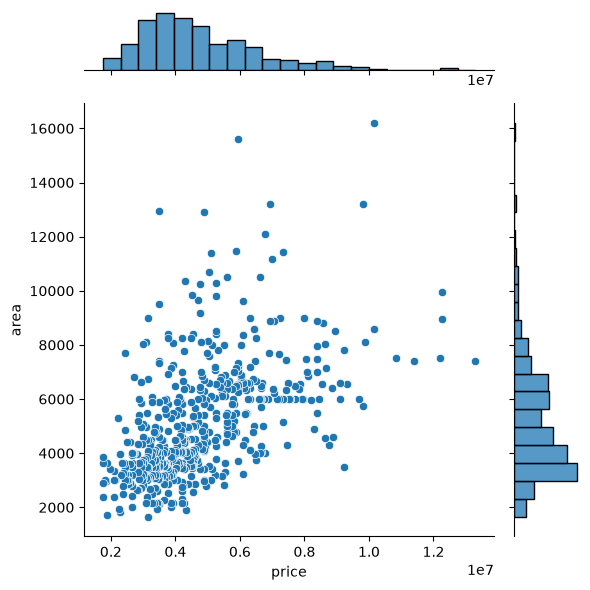

In [35]:
for i in range(len(num_cols)):
    for j in range(i+1,len(num_cols)):
        col1=num_cols[i]
        col2=num_cols[j]
        analyze_numerical_pair(df,col1,col2)

## cat vs cat

In [37]:
def analyze_categorical_pair(df, col1, col2):
    """
    Analyze relationship between two categorical variables
    """
    # Contingency table
    contingency = pd.crosstab(df[col1], df[col2])
    print(f"\nContingency Table: {col1} vs {col2}")
    print(contingency)
    
    # Chi-square test
    from scipy.stats import chi2_contingency
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    print(f"\nChi-square test:")
    print(f"Chi-square statistic: {chi2:.3f}")
    print(f"P-value: {p_value:.3f}")
    print(f"Degrees of freedom: {dof}")
    
    # Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Stacked bar chart
    contingency.plot(kind='bar', stacked=True, ax=axes[0])
    axes[0].set_title(f'Stacked Bar Chart: {col1} vs {col2}')
    axes[0].set_xlabel(col1)
    axes[0].set_ylabel('Count')
    axes[0].legend(title=col2)
    axes[0].tick_params(axis='x', rotation=45)
    
    # Heatmap
    sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues', ax=axes[1])
    axes[1].set_title(f'Heatmap: {col1} vs {col2}')
    
    plt.tight_layout()
    plt.show()




Contingency Table: bedrooms vs bathrooms
bathrooms    1   2  3  4
bedrooms                
1            2   0  0  0
2          128   8  0  0
3          224  72  4  0
4           42  48  4  1
5            4   4  2  0
6            1   1  0  0

Chi-square test:
Chi-square statistic: 97.201
P-value: 0.000
Degrees of freedom: 15


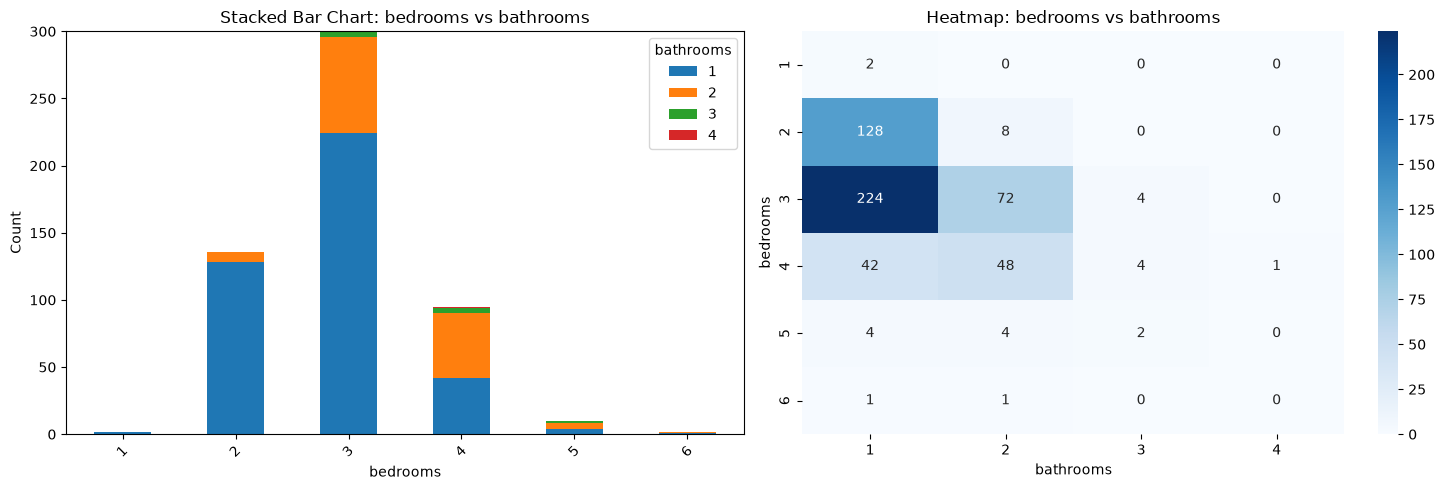


Contingency Table: bedrooms vs stories
stories     1    2   3   4
bedrooms                  
1           2    0   0   0
2         115   20   0   1
3         101  143  31  25
4           8   65   7  15
5           1    8   1   0
6           0    2   0   0

Chi-square test:
Chi-square statistic: 173.308
P-value: 0.000
Degrees of freedom: 15


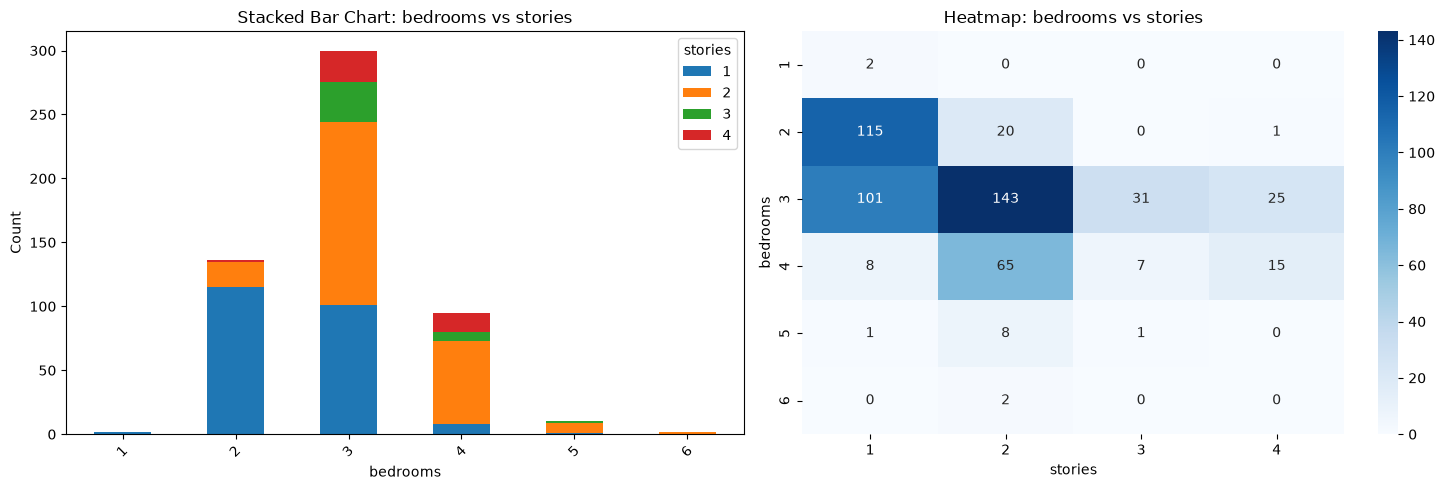


Contingency Table: bedrooms vs mainroad
mainroad  no  yes
bedrooms         
1          1    1
2         20  116
3         39  261
4         13   82
5          4    6
6          0    2

Chi-square test:
Chi-square statistic: 8.335
P-value: 0.139
Degrees of freedom: 5


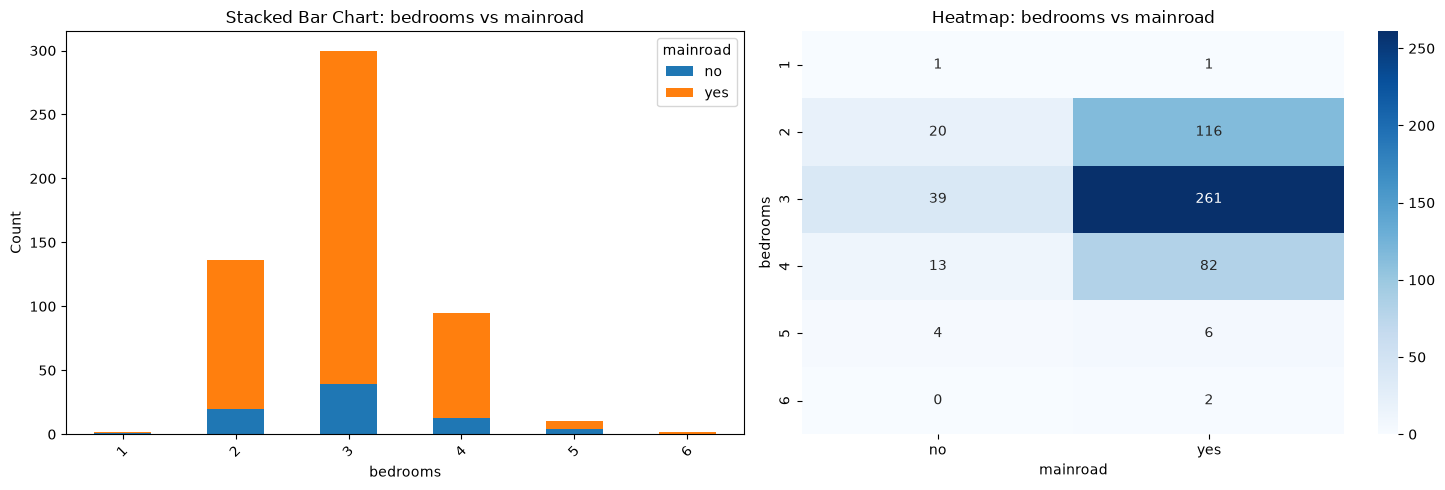


Contingency Table: bedrooms vs guestroom
guestroom   no  yes
bedrooms           
1            2    0
2          120   16
3          242   58
4           74   21
5            8    2
6            2    0

Chi-square test:
Chi-square statistic: 5.971
P-value: 0.309
Degrees of freedom: 5


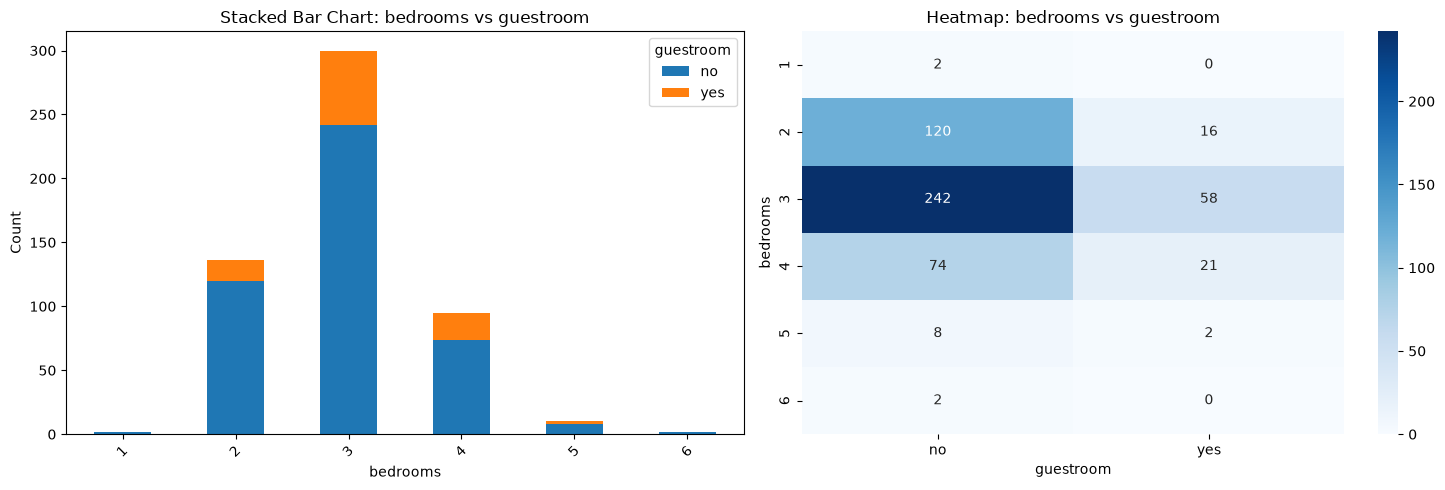


Contingency Table: bedrooms vs basement
basement   no  yes
bedrooms          
1           2    0
2         102   34
3         183  117
4          61   34
5           4    6
6           2    0

Chi-square test:
Chi-square statistic: 13.007
P-value: 0.023
Degrees of freedom: 5


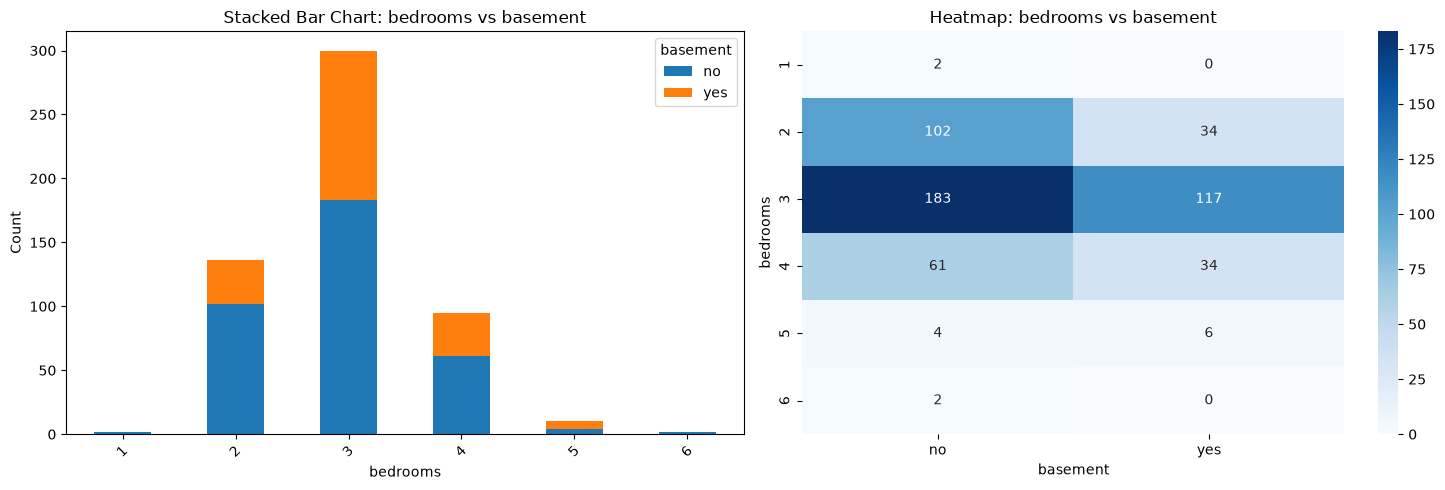


Contingency Table: bedrooms vs hotwaterheating
hotwaterheating   no  yes
bedrooms                 
1                  2    0
2                131    5
3                286   14
4                 91    4
5                  8    2
6                  2    0

Chi-square test:
Chi-square statistic: 5.913
P-value: 0.315
Degrees of freedom: 5


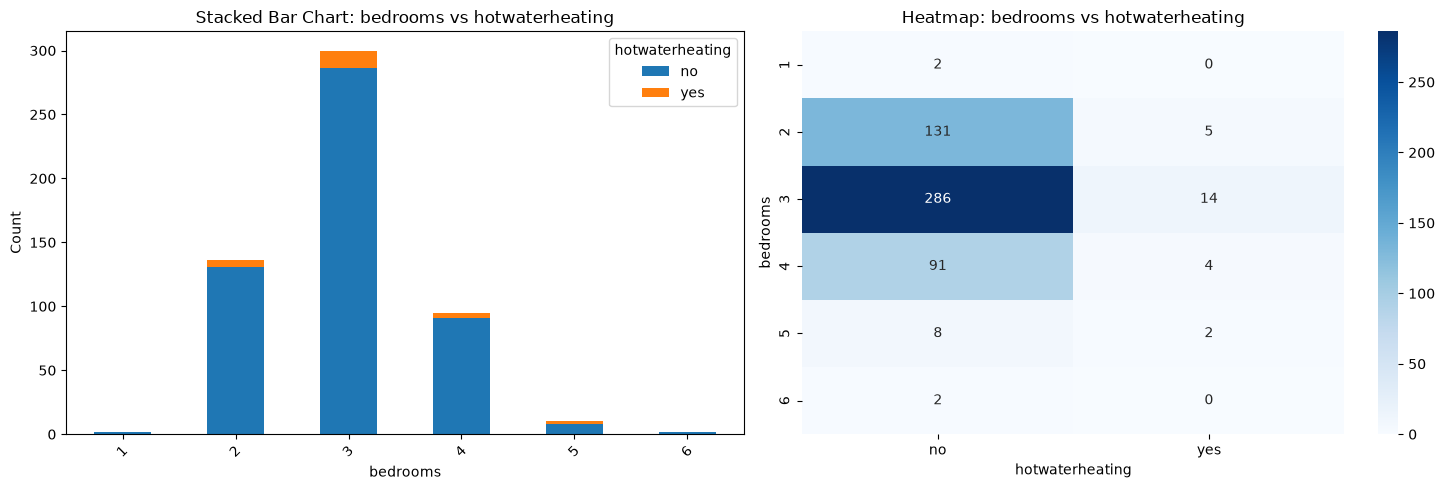


Contingency Table: bedrooms vs airconditioning
airconditioning   no  yes
bedrooms                 
1                  2    0
2                114   22
3                193  107
4                 55   40
5                  7    3
6                  2    0

Chi-square test:
Chi-square statistic: 23.990
P-value: 0.000
Degrees of freedom: 5


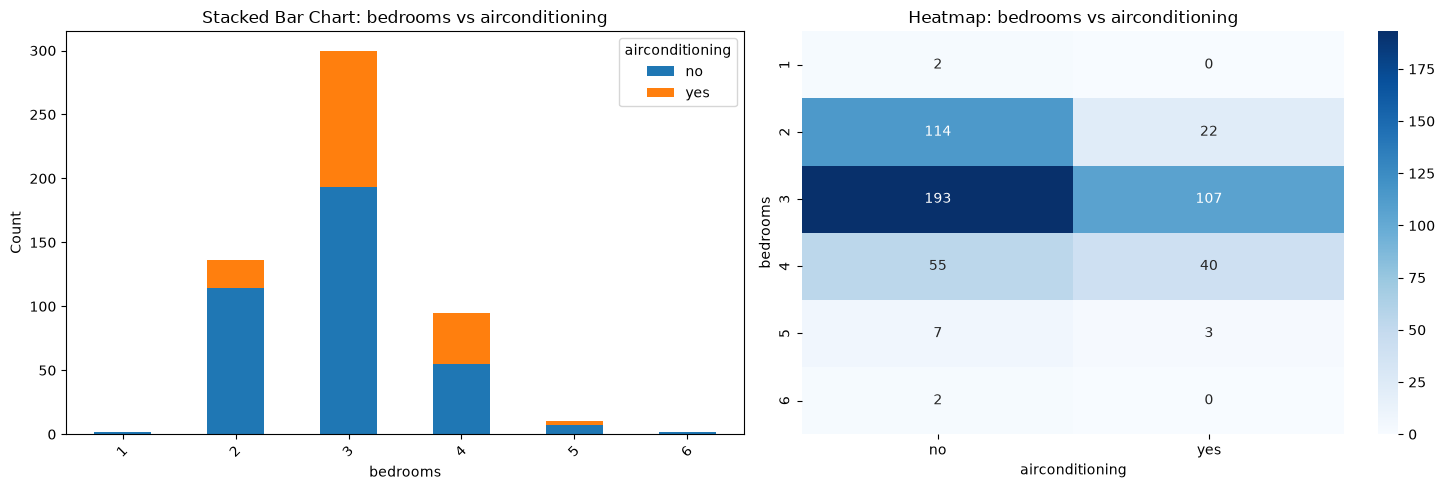


Contingency Table: bedrooms vs parking
parking     0   1   2  3
bedrooms                
1           2   0   0  0
2          86  34  15  1
3         163  64  66  7
4          41  25  25  4
5           6   2   2  0
6           1   1   0  0

Chi-square test:
Chi-square statistic: 19.336
P-value: 0.199
Degrees of freedom: 15


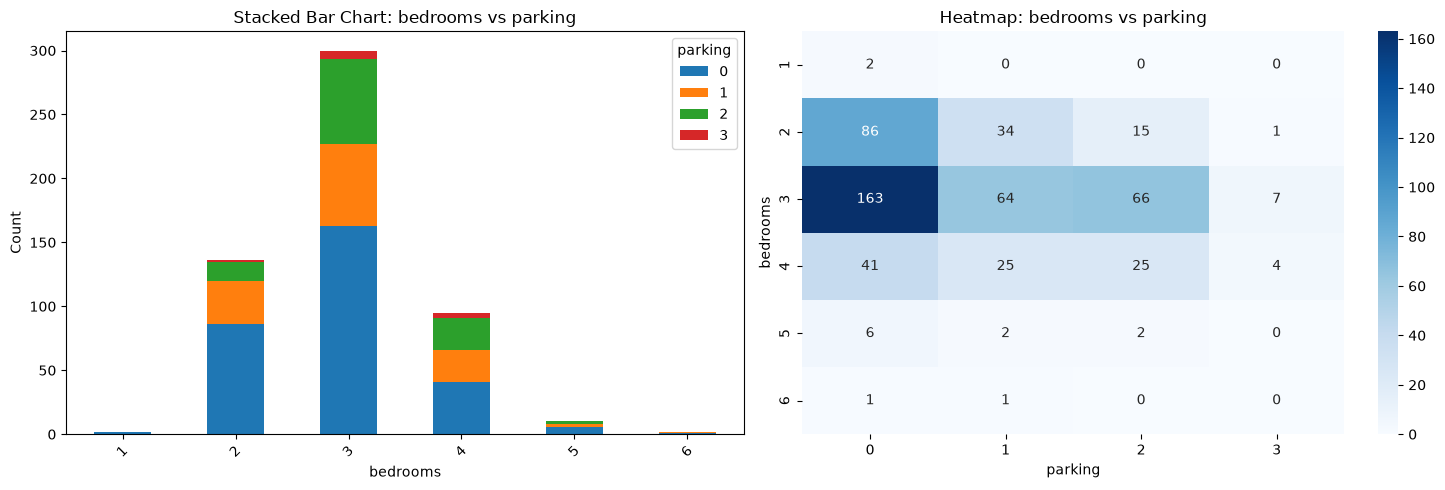


Contingency Table: bedrooms vs prefarea
prefarea   no  yes
bedrooms          
1           2    0
2         120   16
3         212   88
4          72   23
5           9    1
6           2    0

Chi-square test:
Chi-square statistic: 18.373
P-value: 0.003
Degrees of freedom: 5


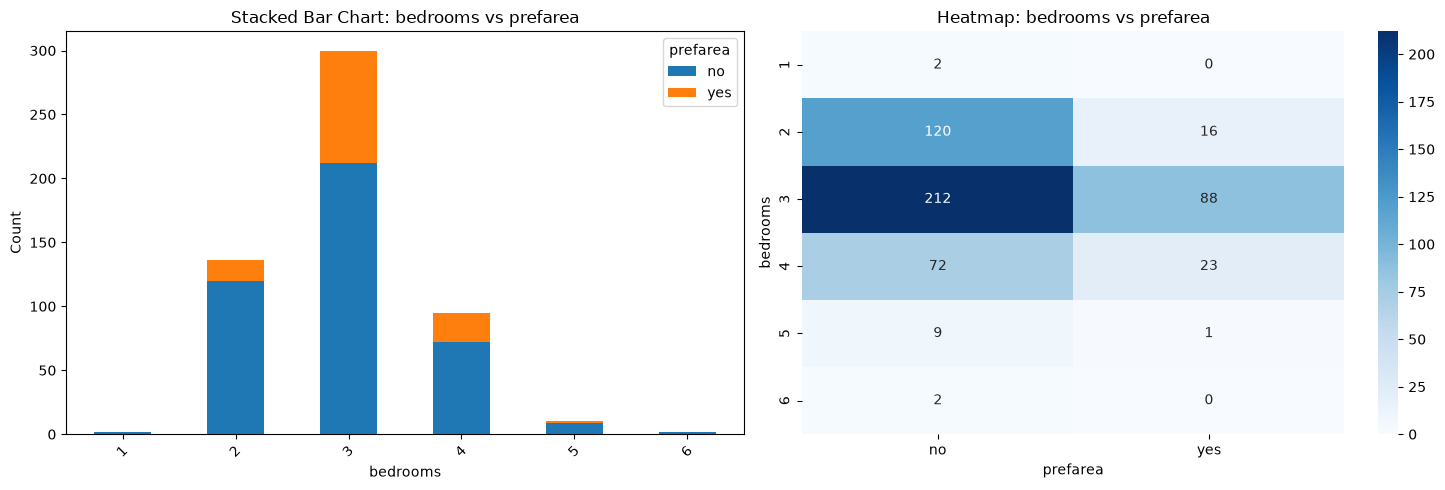


Contingency Table: bedrooms vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
bedrooms                                                
1                         1               0            1
2                        29              50           57
3                        76             127           97
4                        29              48           18
5                         4               2            4
6                         1               0            1

Chi-square test:
Chi-square statistic: 18.585
P-value: 0.046
Degrees of freedom: 10


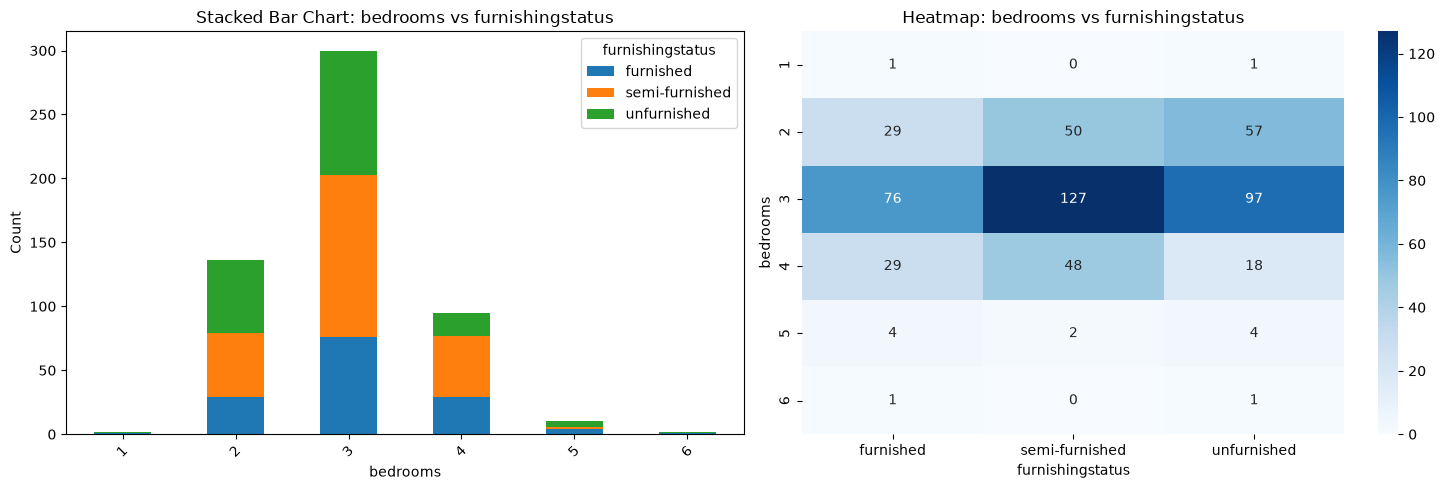


Contingency Table: bathrooms vs stories
stories      1    2   3   4
bathrooms                  
1          197  167  25  12
2           29   63  14  27
3            1    8   0   1
4            0    0   0   1

Chi-square test:
Chi-square statistic: 79.662
P-value: 0.000
Degrees of freedom: 9


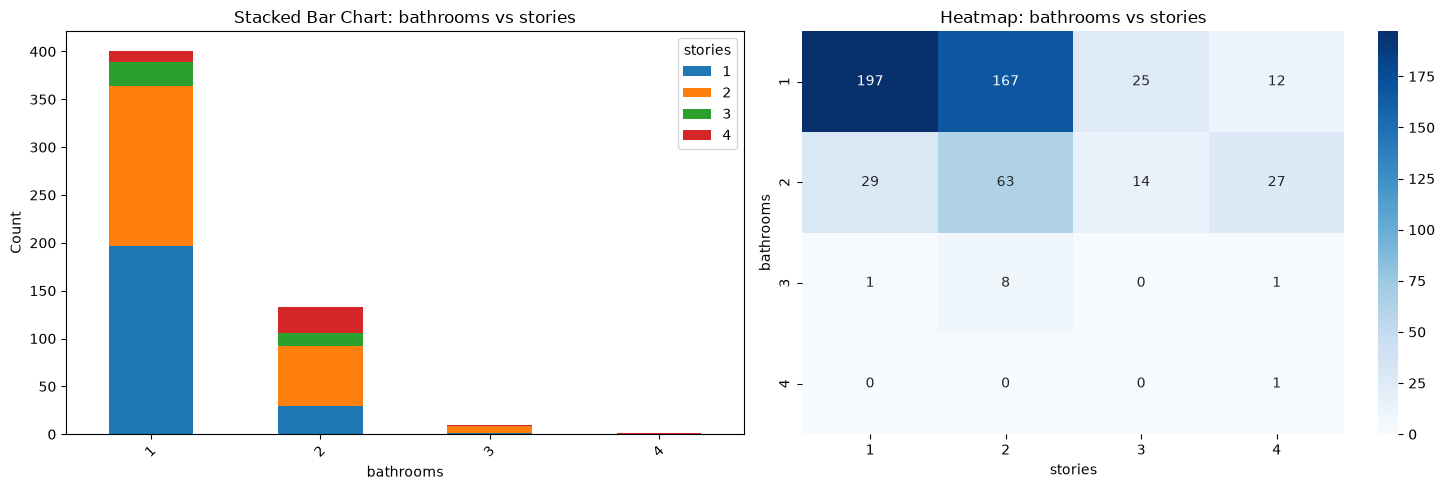


Contingency Table: bathrooms vs mainroad
mainroad   no  yes
bathrooms         
1          61  340
2          14  119
3           2    8
4           0    1

Chi-square test:
Chi-square statistic: 2.259
P-value: 0.520
Degrees of freedom: 3


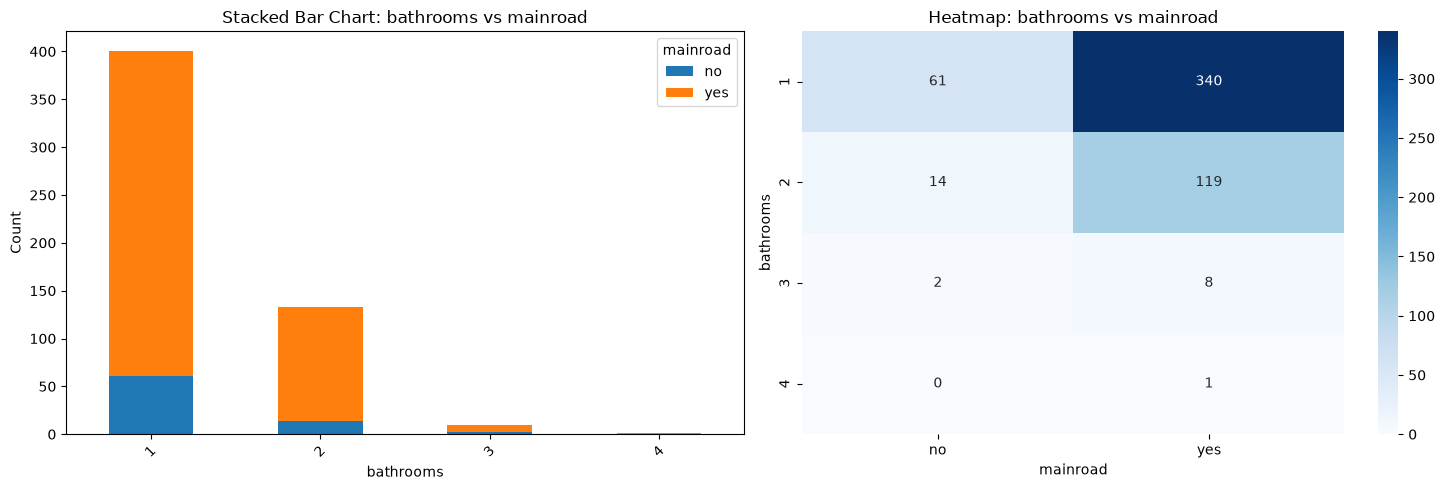


Contingency Table: bathrooms vs guestroom
guestroom   no  yes
bathrooms          
1          342   59
2           98   35
3            7    3
4            1    0

Chi-square test:
Chi-square statistic: 10.438
P-value: 0.015
Degrees of freedom: 3


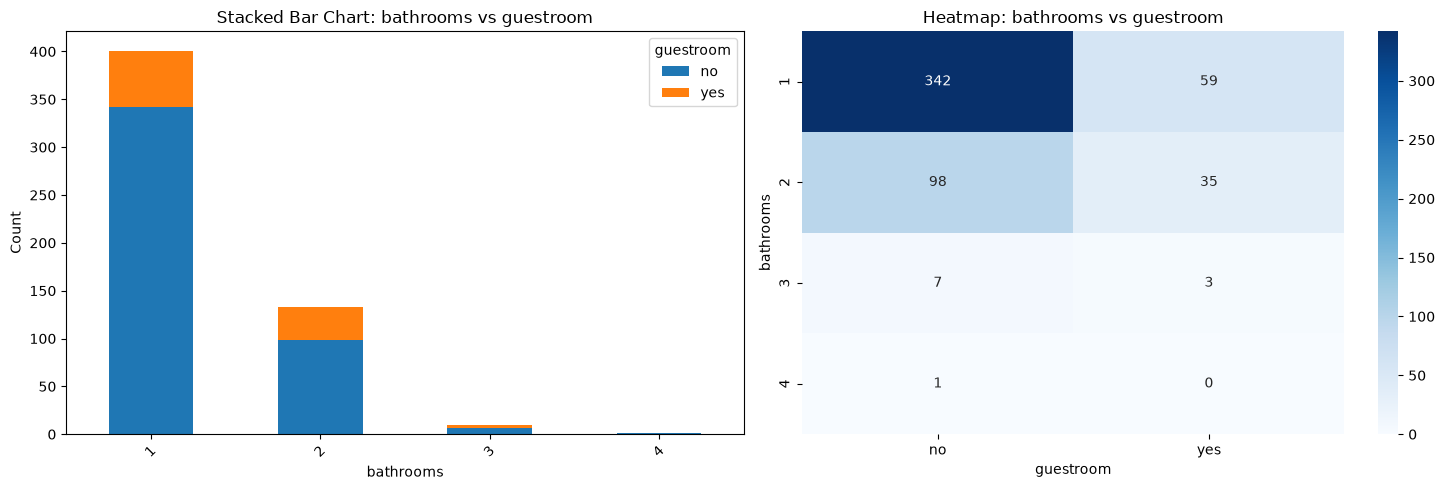


Contingency Table: bathrooms vs basement
basement    no  yes
bathrooms          
1          273  128
2           75   58
3            5    5
4            1    0

Chi-square test:
Chi-square statistic: 7.527
P-value: 0.057
Degrees of freedom: 3


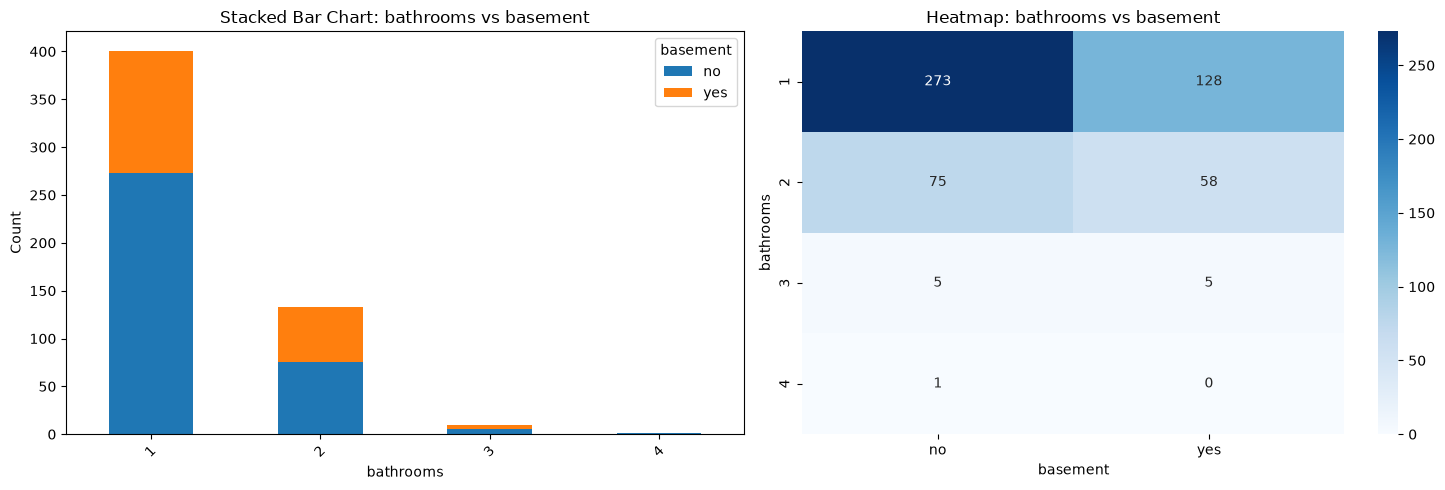


Contingency Table: bathrooms vs hotwaterheating
hotwaterheating   no  yes
bathrooms                
1                386   15
2                124    9
3                  9    1
4                  1    0

Chi-square test:
Chi-square statistic: 2.818
P-value: 0.421
Degrees of freedom: 3


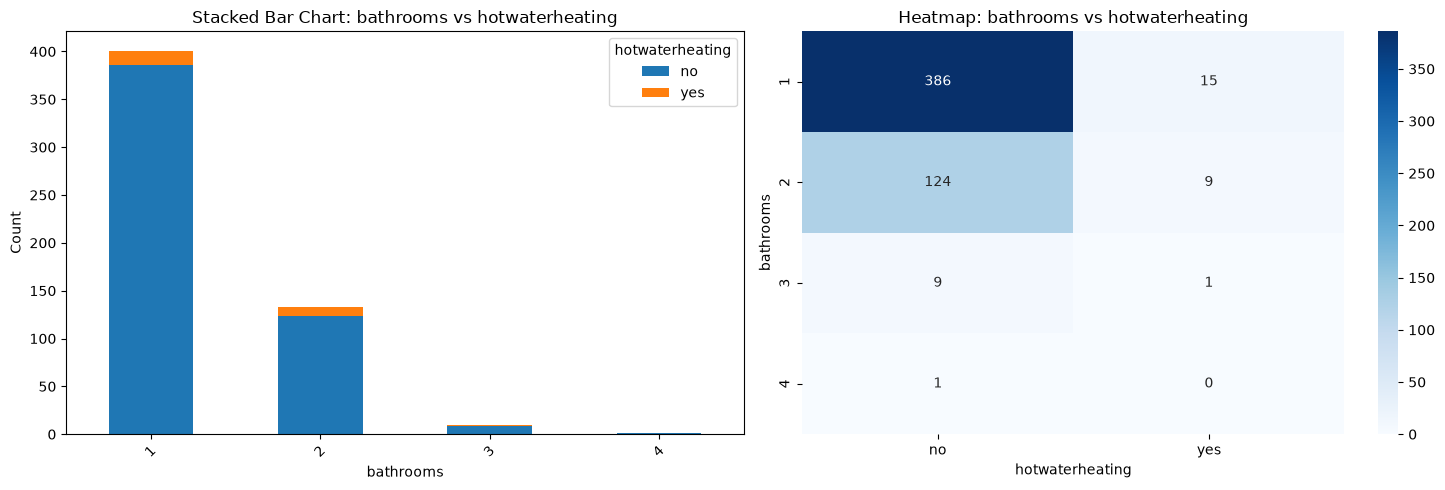


Contingency Table: bathrooms vs airconditioning
airconditioning   no  yes
bathrooms                
1                298  103
2                 67   66
3                  8    2
4                  0    1

Chi-square test:
Chi-square statistic: 29.286
P-value: 0.000
Degrees of freedom: 3


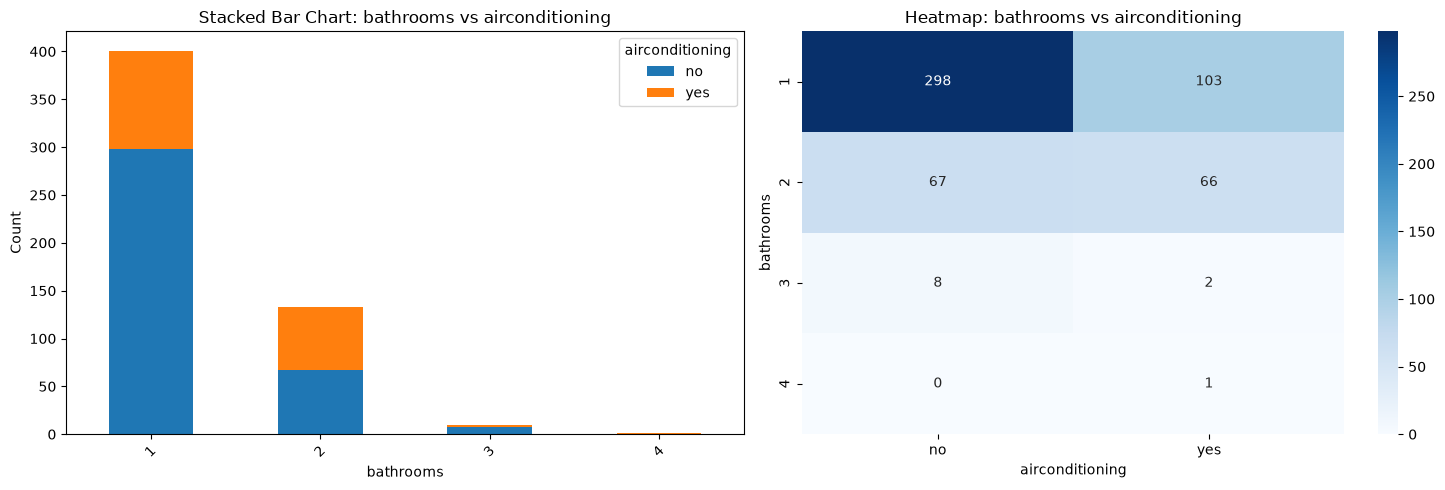


Contingency Table: bathrooms vs parking
parking      0   1   2  3
bathrooms                
1          241  83  69  8
2           54  42  34  3
3            4   1   5  0
4            0   0   0  1

Chi-square test:
Chi-square statistic: 66.125
P-value: 0.000
Degrees of freedom: 9


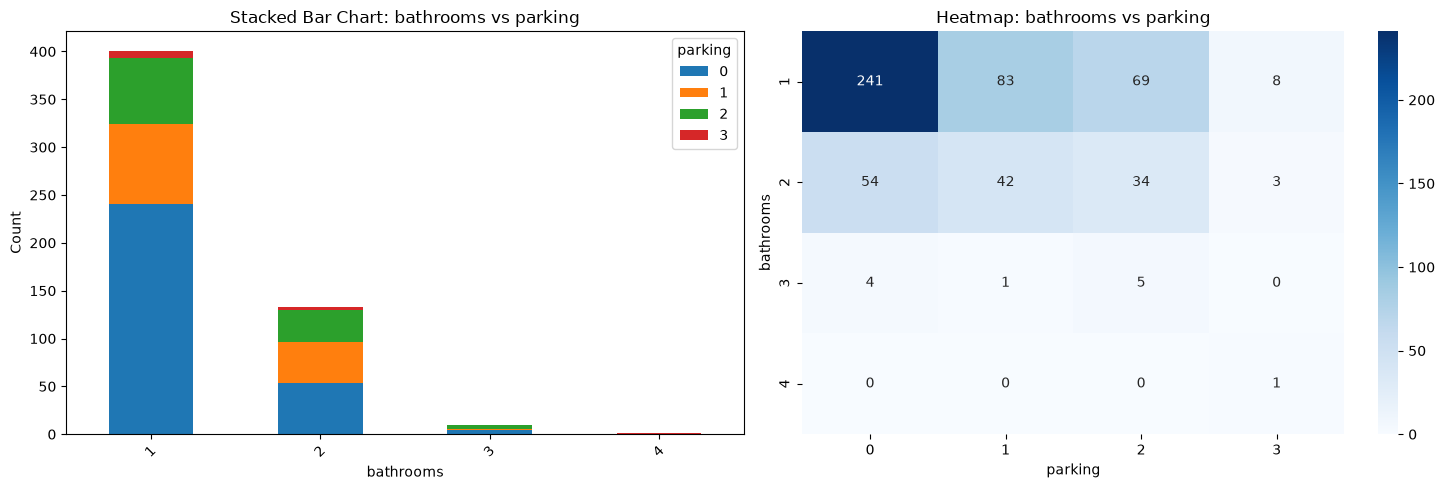


Contingency Table: bathrooms vs prefarea
prefarea    no  yes
bathrooms          
1          315   86
2           93   40
3            8    2
4            1    0

Chi-square test:
Chi-square statistic: 4.516
P-value: 0.211
Degrees of freedom: 3


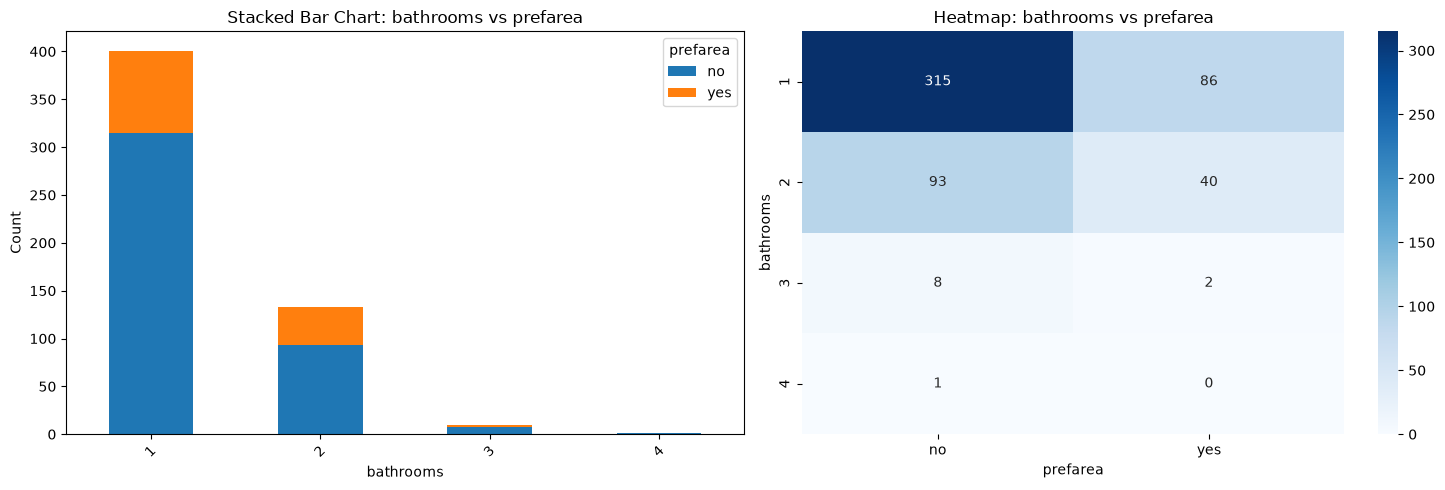


Contingency Table: bathrooms vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
bathrooms                                               
1                        90             164          147
2                        48              57           28
3                         1               6            3
4                         1               0            0

Chi-square test:
Chi-square statistic: 19.477
P-value: 0.003
Degrees of freedom: 6


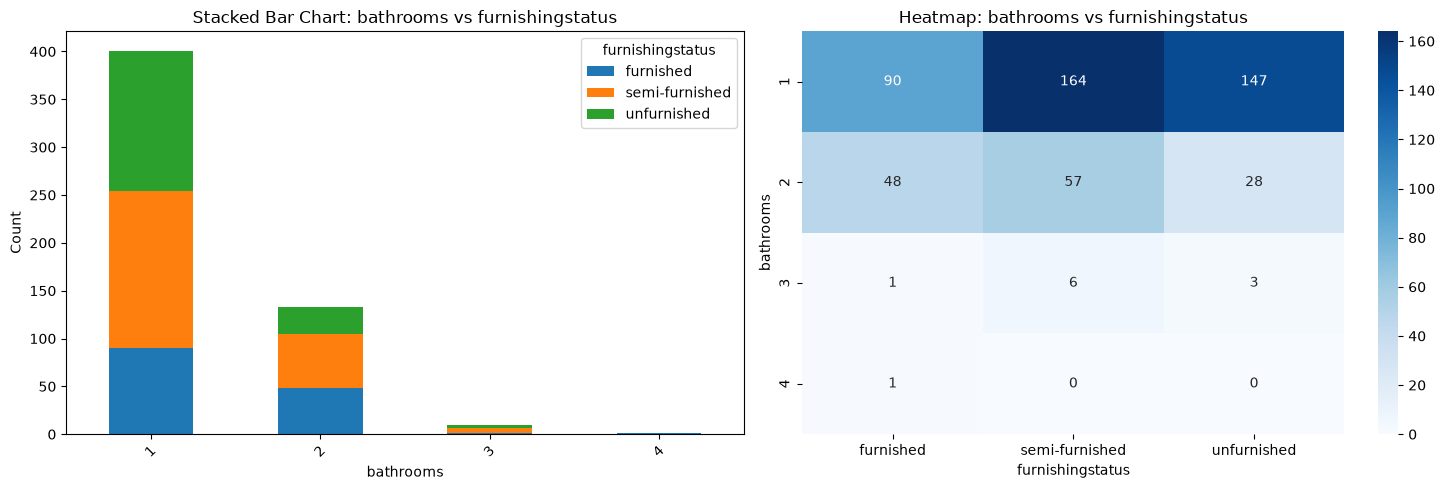


Contingency Table: stories vs mainroad
mainroad  no  yes
stories          
1         37  190
2         38  200
3          2   37
4          0   41

Chi-square test:
Chi-square statistic: 10.894
P-value: 0.012
Degrees of freedom: 3


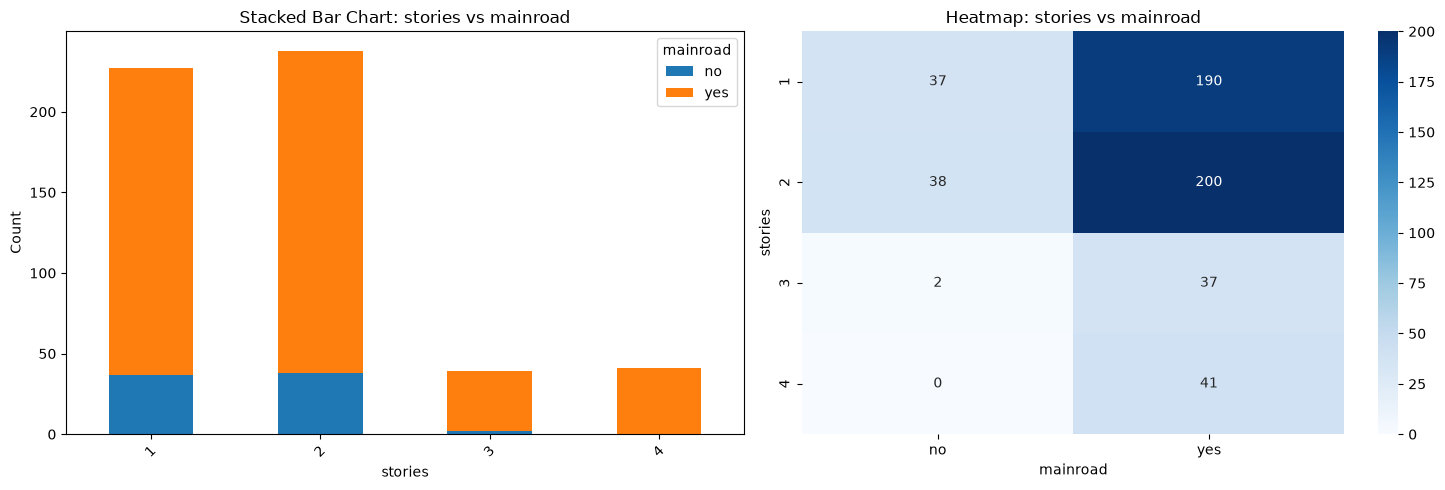


Contingency Table: stories vs guestroom
guestroom   no  yes
stories            
1          189   38
2          195   43
3           34    5
4           30   11

Chi-square test:
Chi-square statistic: 3.132
P-value: 0.372
Degrees of freedom: 3


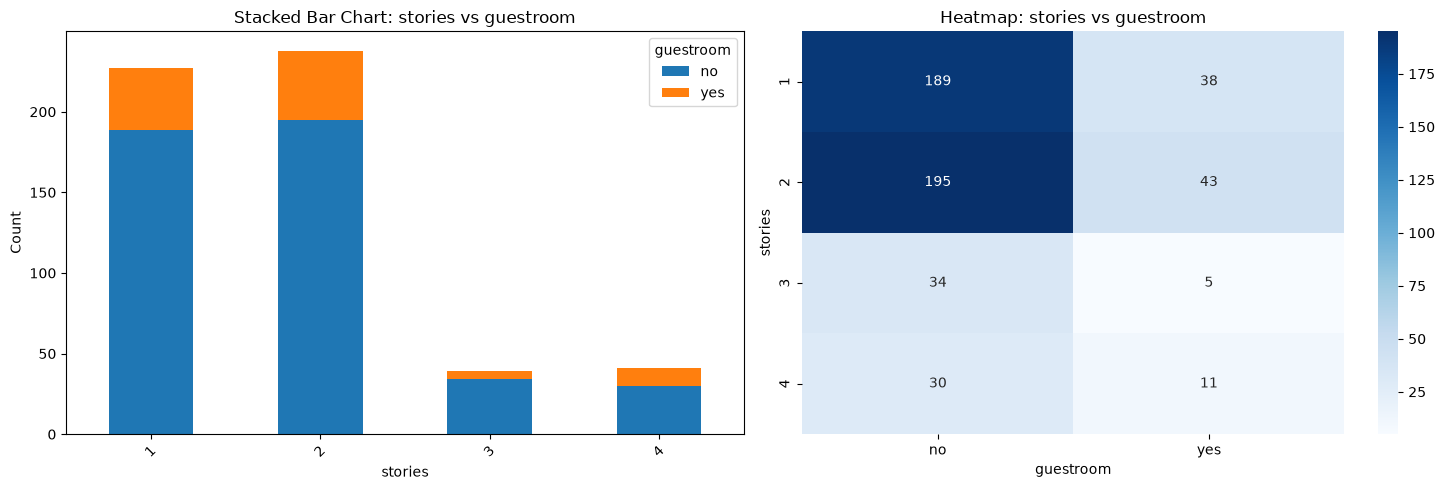


Contingency Table: stories vs basement
basement   no  yes
stories           
1         140   87
2         142   96
3          34    5
4          38    3

Chi-square test:
Chi-square statistic: 26.310
P-value: 0.000
Degrees of freedom: 3


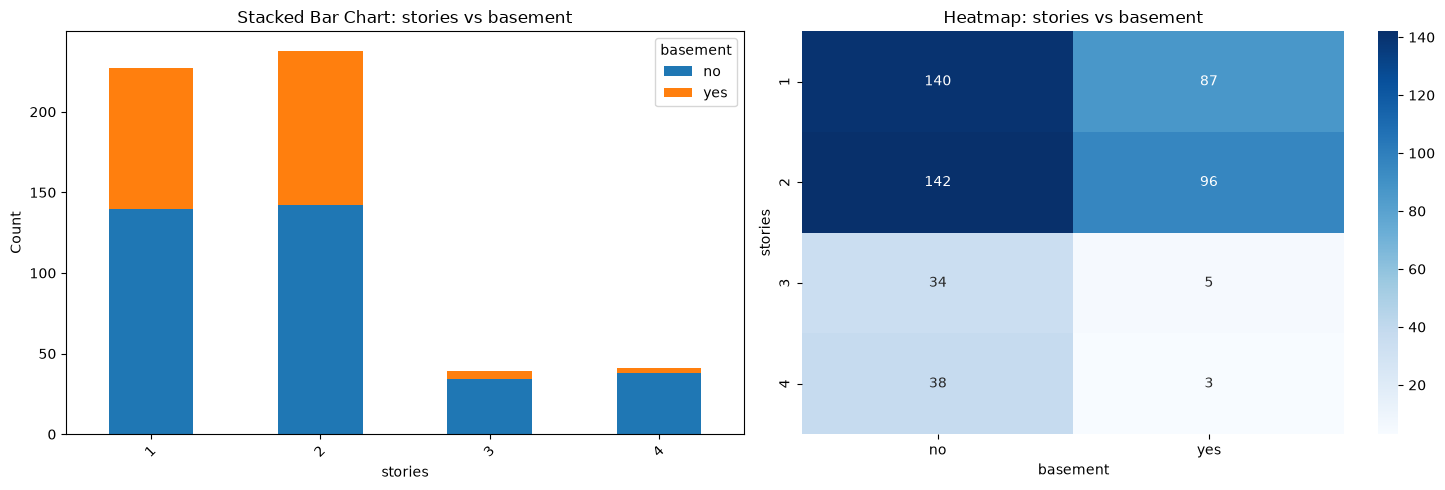


Contingency Table: stories vs hotwaterheating
hotwaterheating   no  yes
stories                  
1                220    7
2                224   14
3                 35    4
4                 41    0

Chi-square test:
Chi-square statistic: 6.920
P-value: 0.075
Degrees of freedom: 3


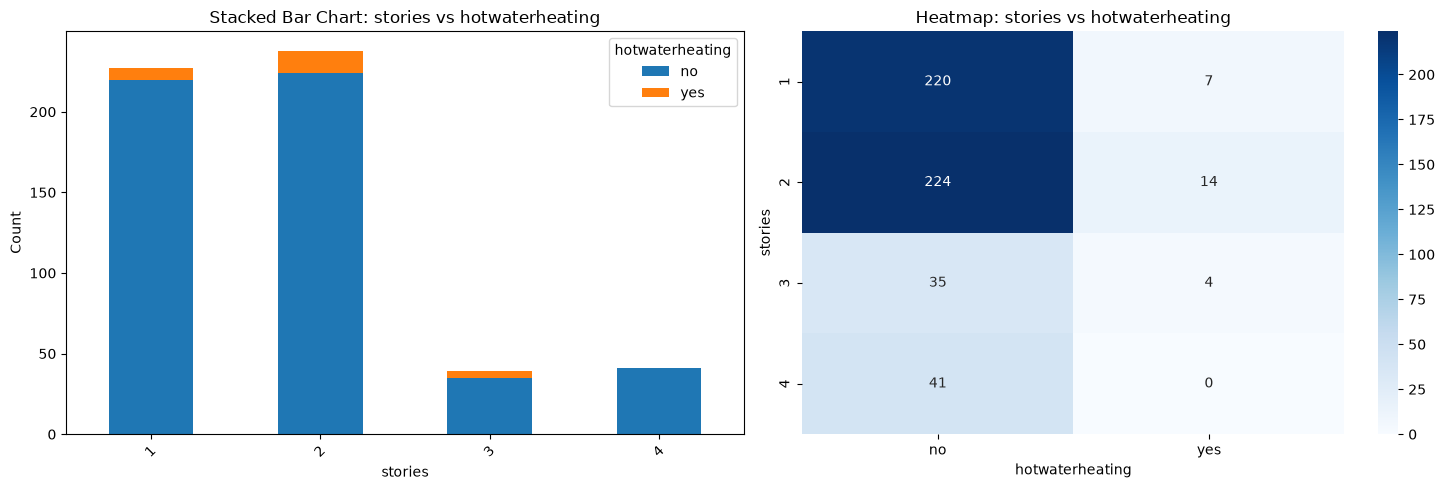


Contingency Table: stories vs airconditioning
airconditioning   no  yes
stories                  
1                173   54
2                172   66
3                 20   19
4                  8   33

Chi-square test:
Chi-square statistic: 58.720
P-value: 0.000
Degrees of freedom: 3


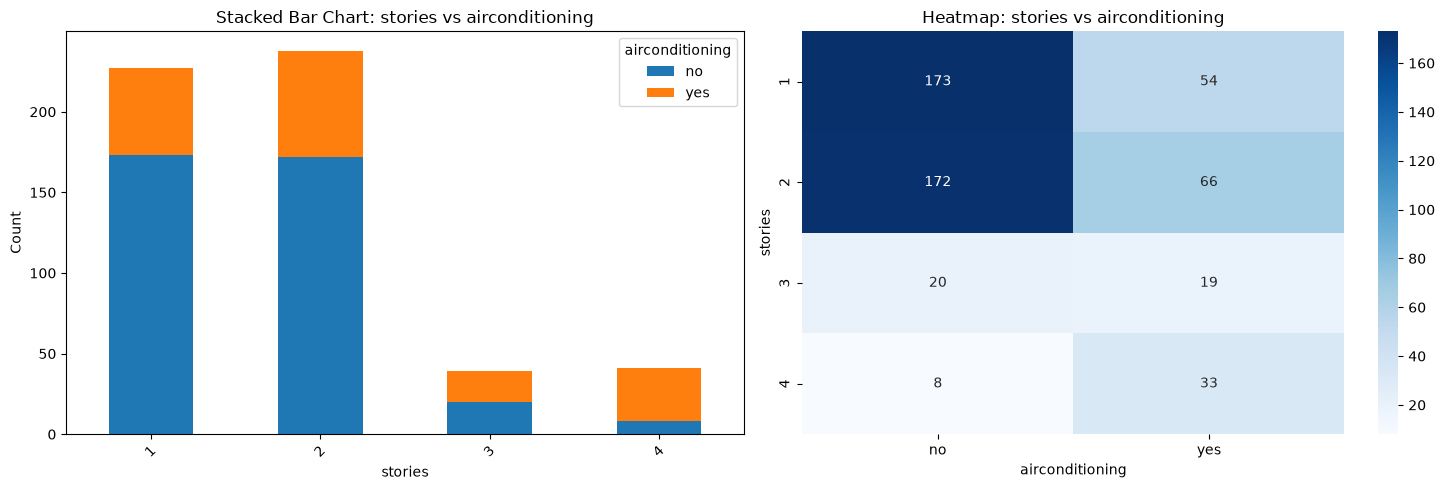


Contingency Table: stories vs parking
parking    0   1   2  3
stories                
1        127  45  49  6
2        131  62  42  3
3         27   6   6  0
4         14  13  11  3

Chi-square test:
Chi-square statistic: 18.210
P-value: 0.033
Degrees of freedom: 9


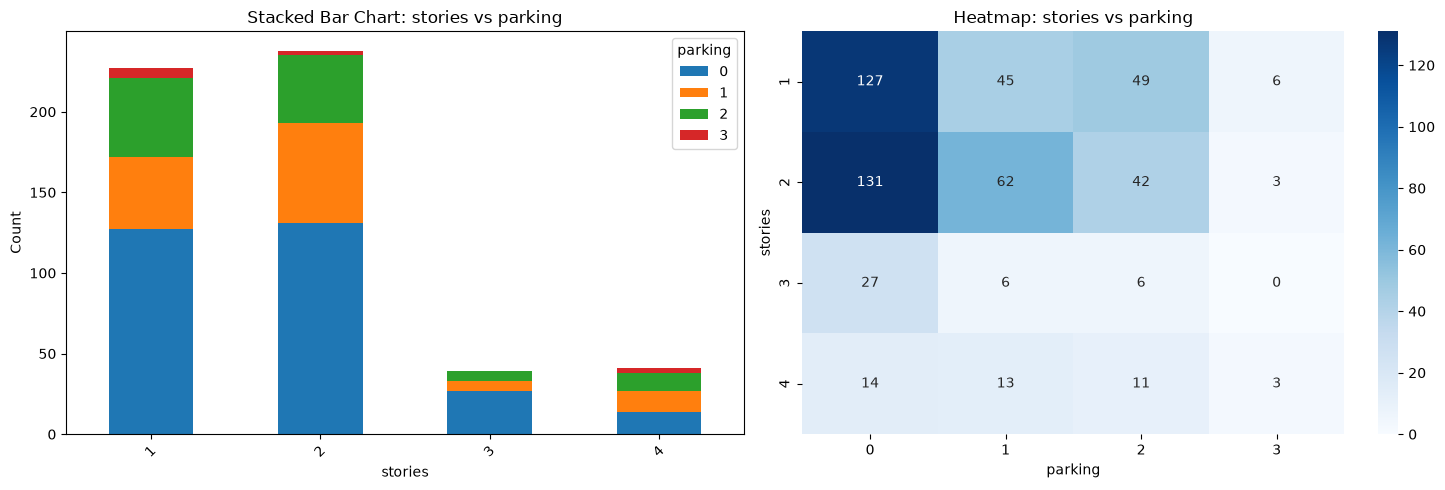


Contingency Table: stories vs prefarea
prefarea   no  yes
stories           
1         175   52
2         189   49
3          21   18
4          32    9

Chi-square test:
Chi-square statistic: 12.360
P-value: 0.006
Degrees of freedom: 3


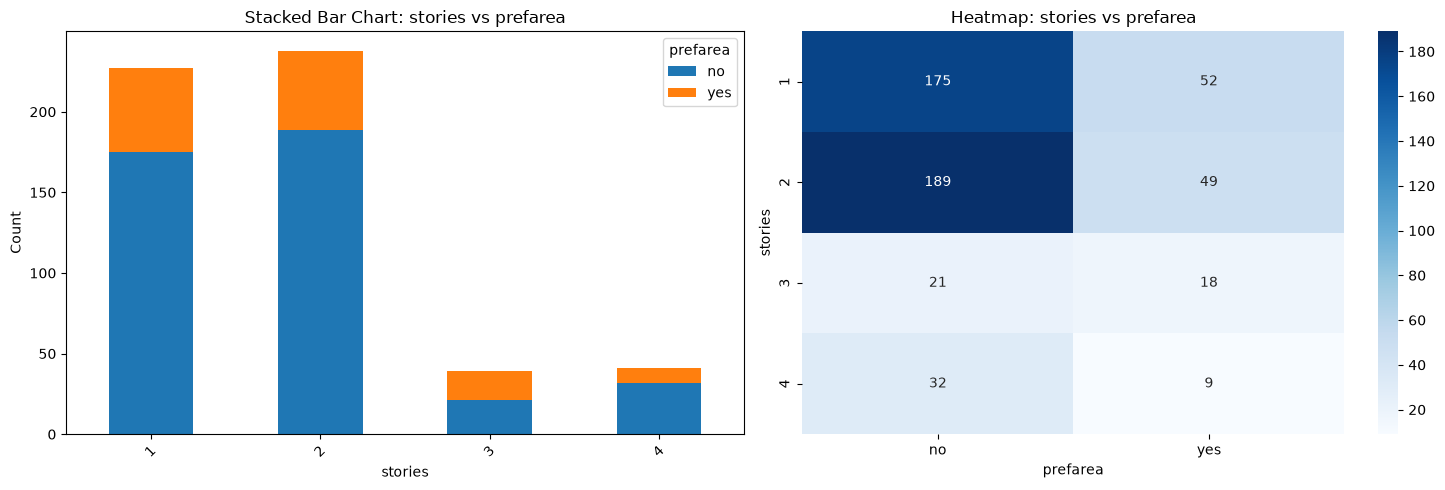


Contingency Table: stories vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
stories                                                 
1                        53              85           89
2                        58             115           65
3                        13              14           12
4                        16              13           12

Chi-square test:
Chi-square statistic: 14.411
P-value: 0.025
Degrees of freedom: 6


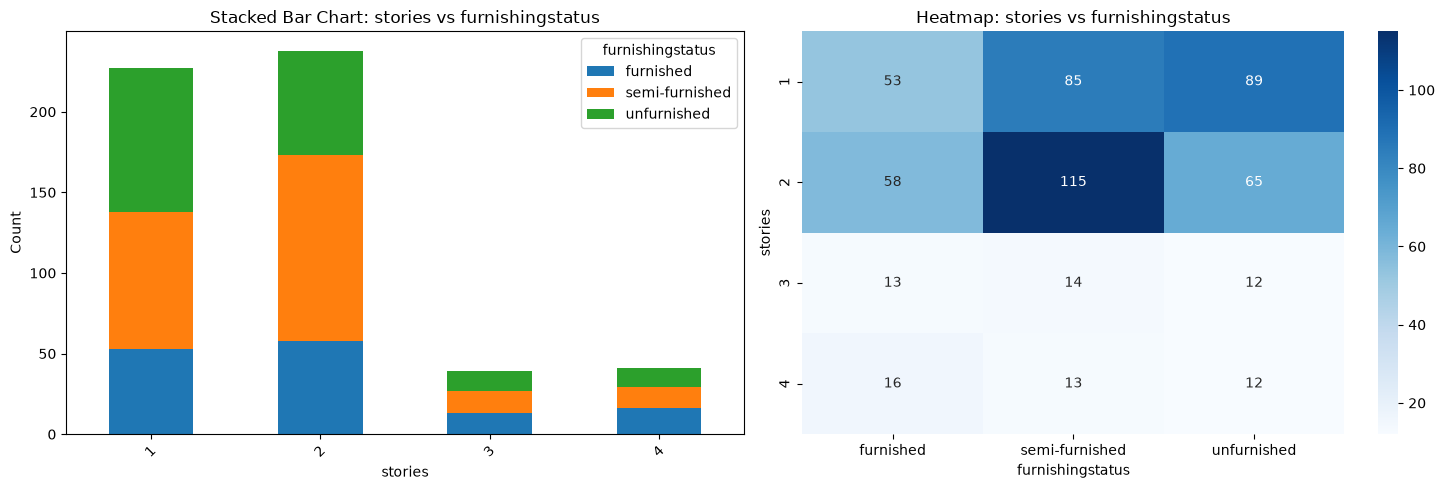


Contingency Table: mainroad vs guestroom
guestroom   no  yes
mainroad           
no          70    7
yes        378   90

Chi-square test:
Chi-square statistic: 3.980
P-value: 0.046
Degrees of freedom: 1


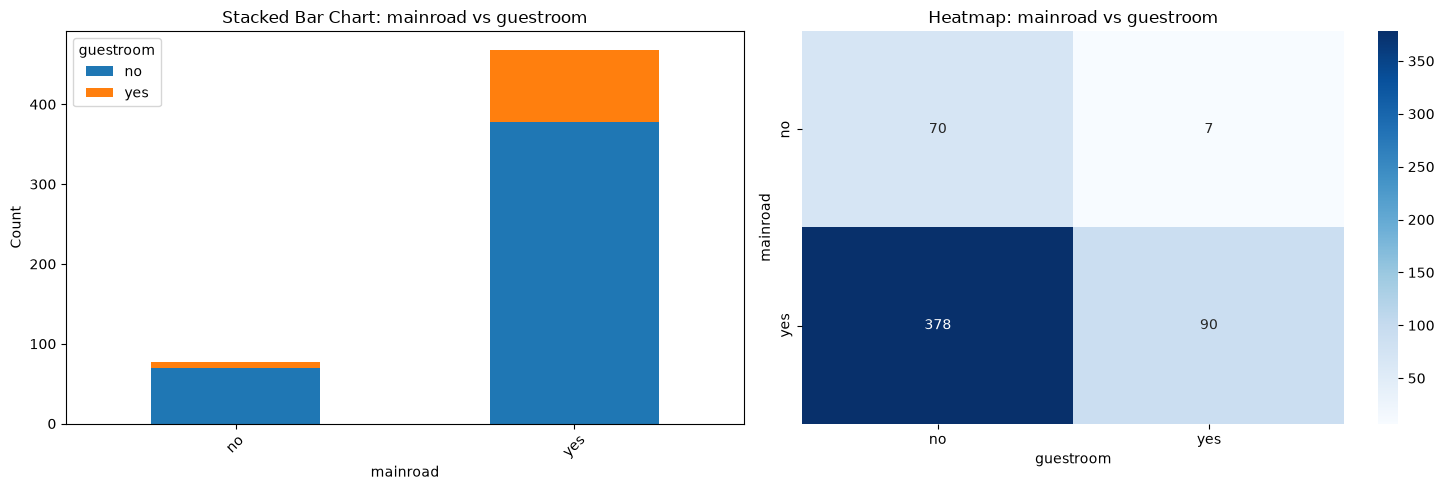


Contingency Table: mainroad vs basement
basement   no  yes
mainroad          
no         54   23
yes       300  168

Chi-square test:
Chi-square statistic: 0.807
P-value: 0.369
Degrees of freedom: 1


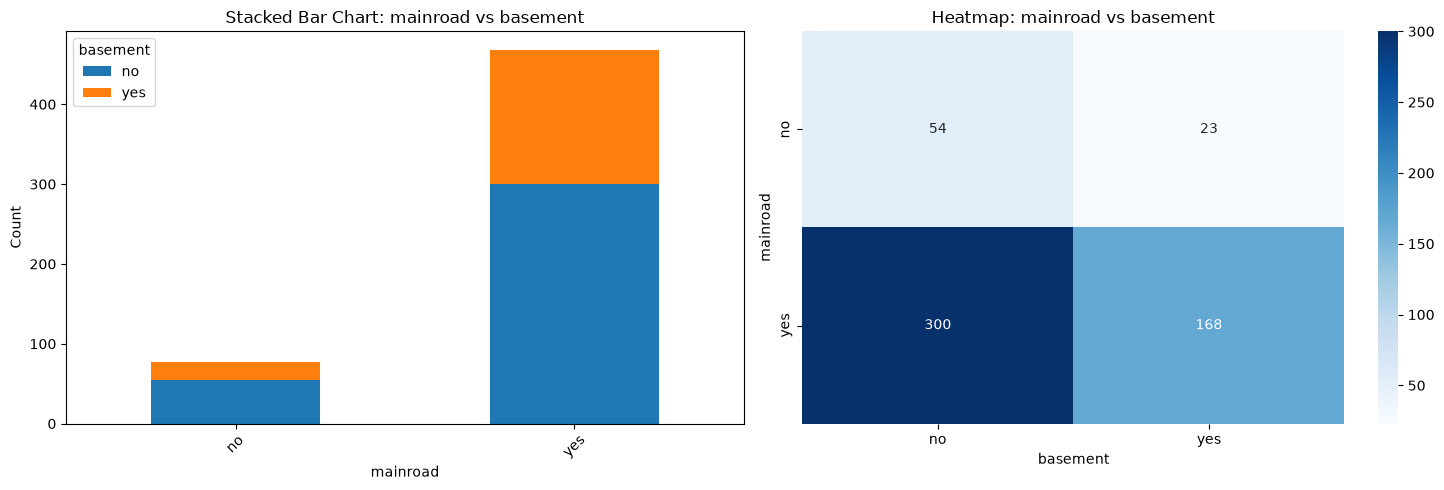


Contingency Table: mainroad vs hotwaterheating
hotwaterheating   no  yes
mainroad                 
no                73    4
yes              447   21

Chi-square test:
Chi-square statistic: 0.000
P-value: 1.000
Degrees of freedom: 1


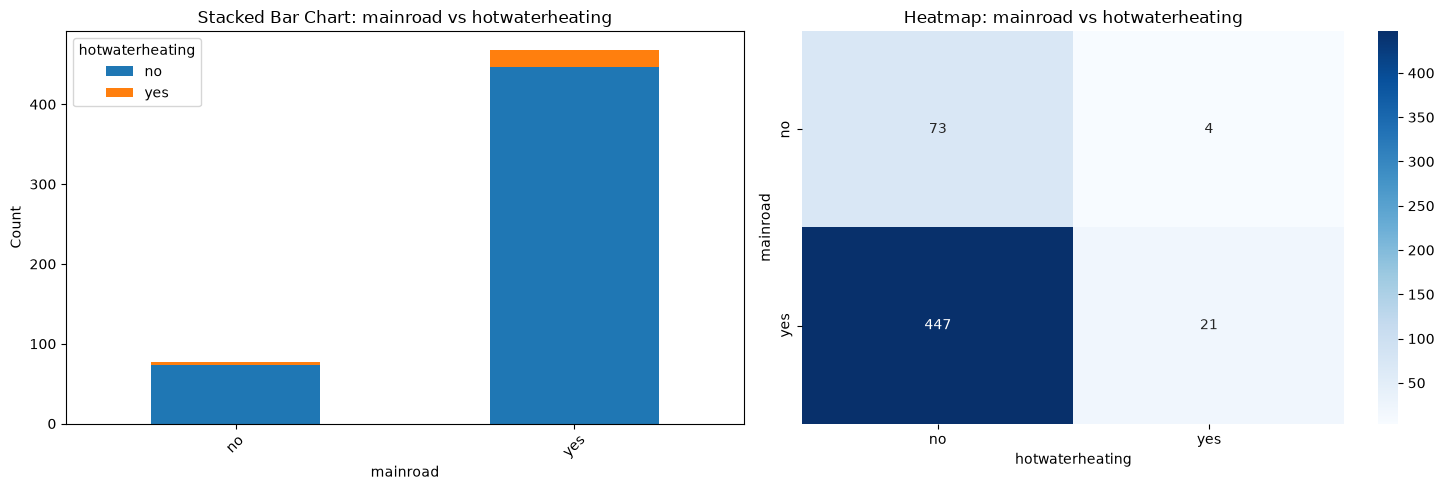


Contingency Table: mainroad vs airconditioning
airconditioning   no  yes
mainroad                 
no                62   15
yes              311  157

Chi-square test:
Chi-square statistic: 5.423
P-value: 0.020
Degrees of freedom: 1


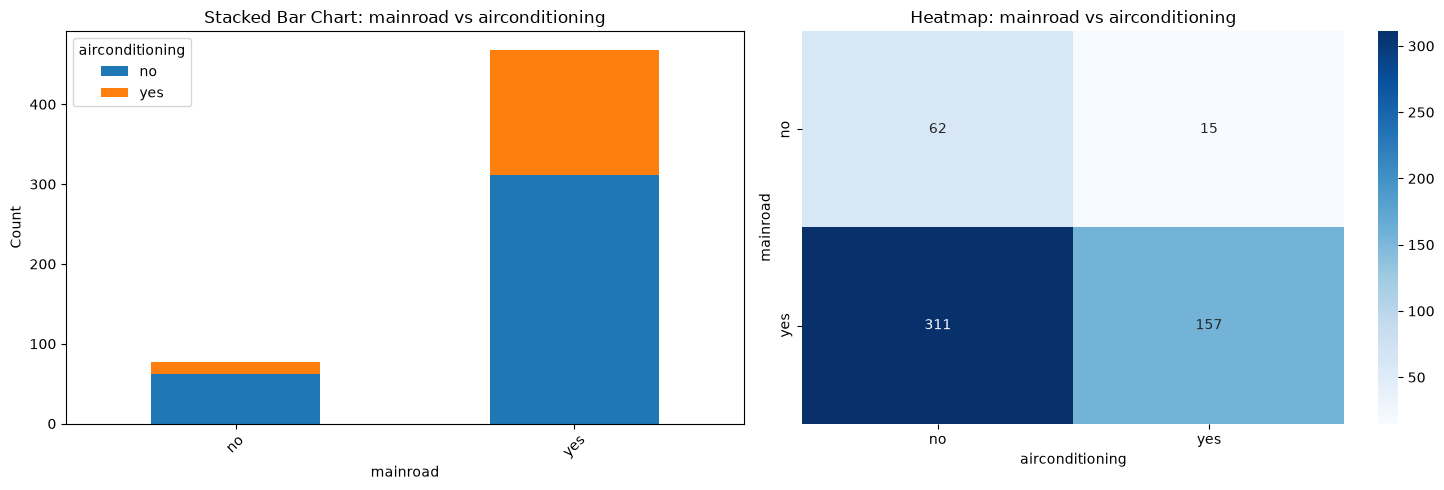


Contingency Table: mainroad vs parking
parking     0    1    2   3
mainroad                   
no         58   18    1   0
yes       241  108  107  12

Chi-square test:
Chi-square statistic: 24.337
P-value: 0.000
Degrees of freedom: 3


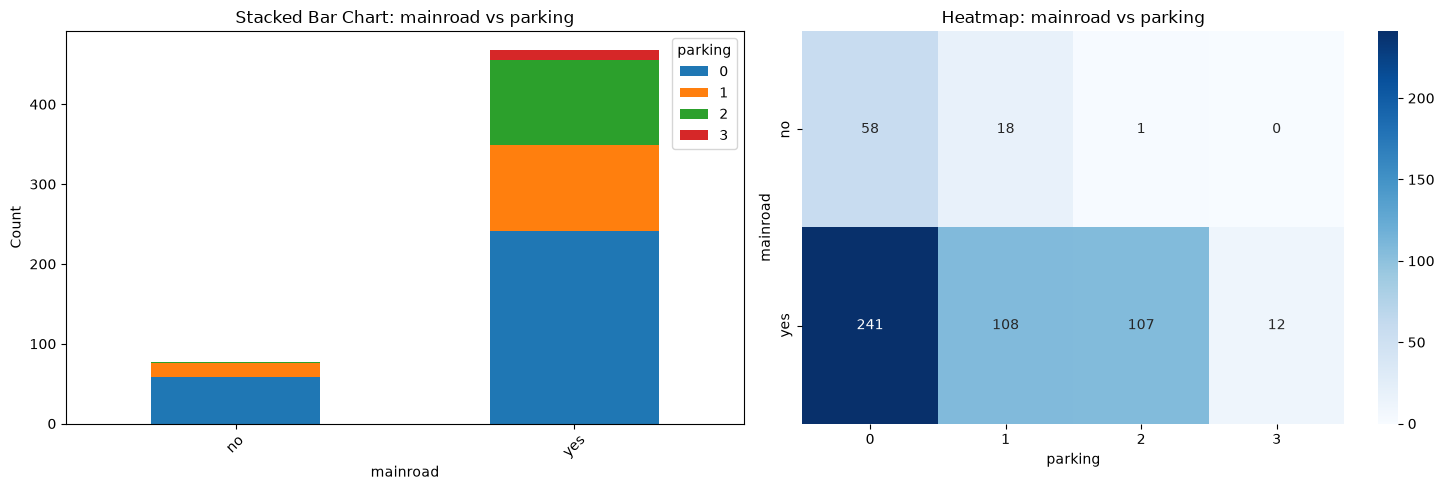


Contingency Table: mainroad vs prefarea
prefarea   no  yes
mainroad          
no         75    2
yes       342  126

Chi-square test:
Chi-square statistic: 20.440
P-value: 0.000
Degrees of freedom: 1


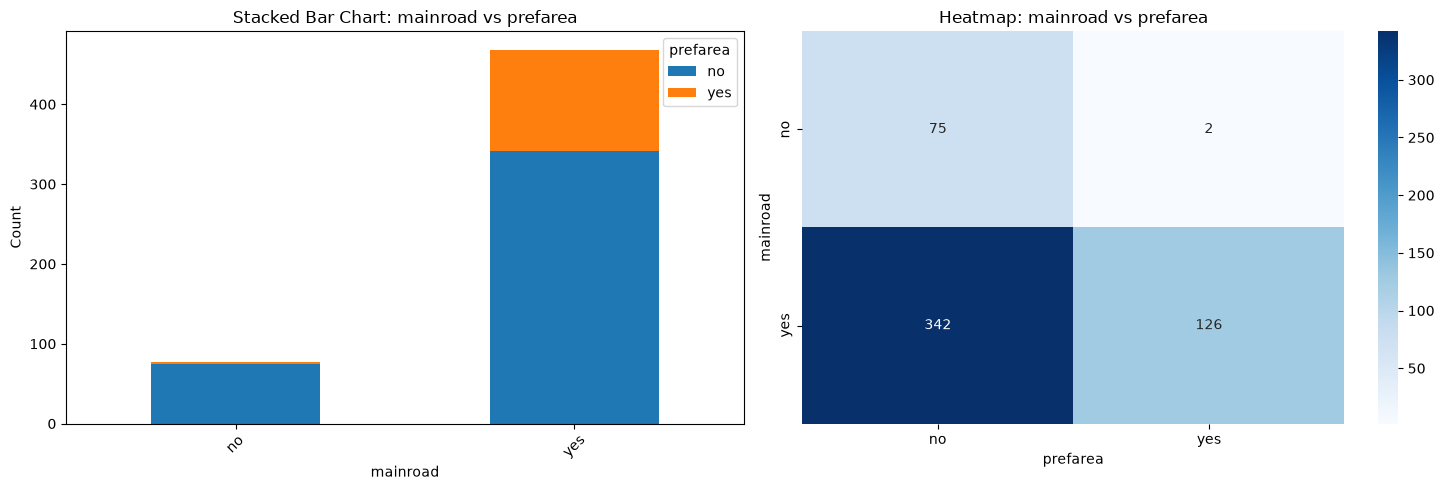


Contingency Table: mainroad vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
mainroad                                                
no                        9              31           37
yes                     131             196          141

Chi-square test:
Chi-square statistic: 13.387
P-value: 0.001
Degrees of freedom: 2


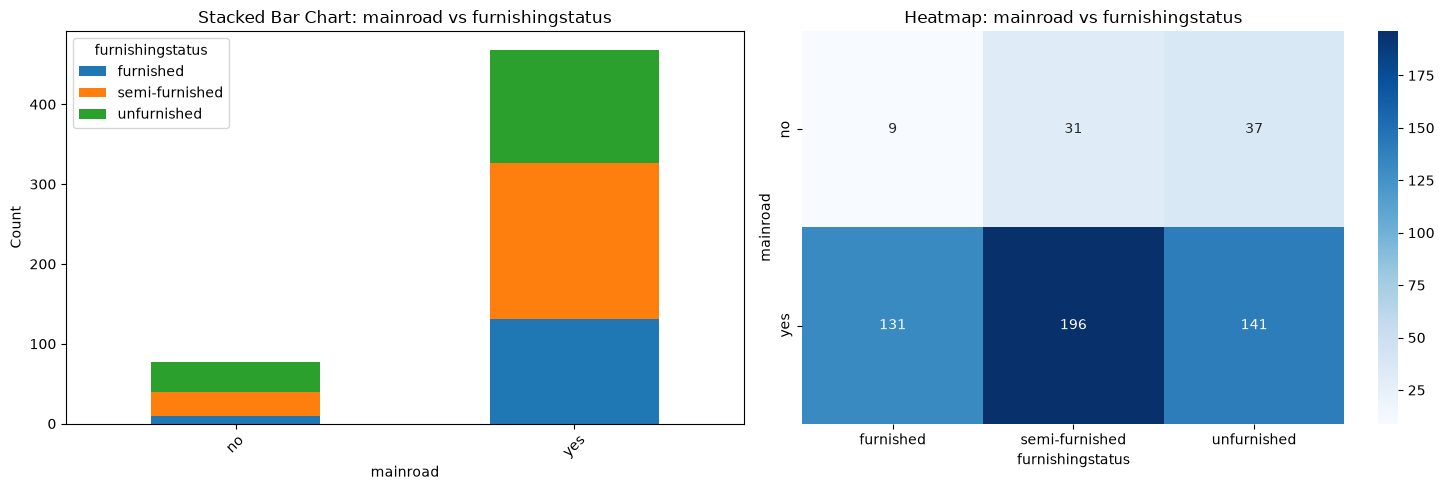


Contingency Table: guestroom vs basement
basement    no  yes
guestroom          
no         328  120
yes         26   71

Chi-square test:
Chi-square statistic: 73.421
P-value: 0.000
Degrees of freedom: 1


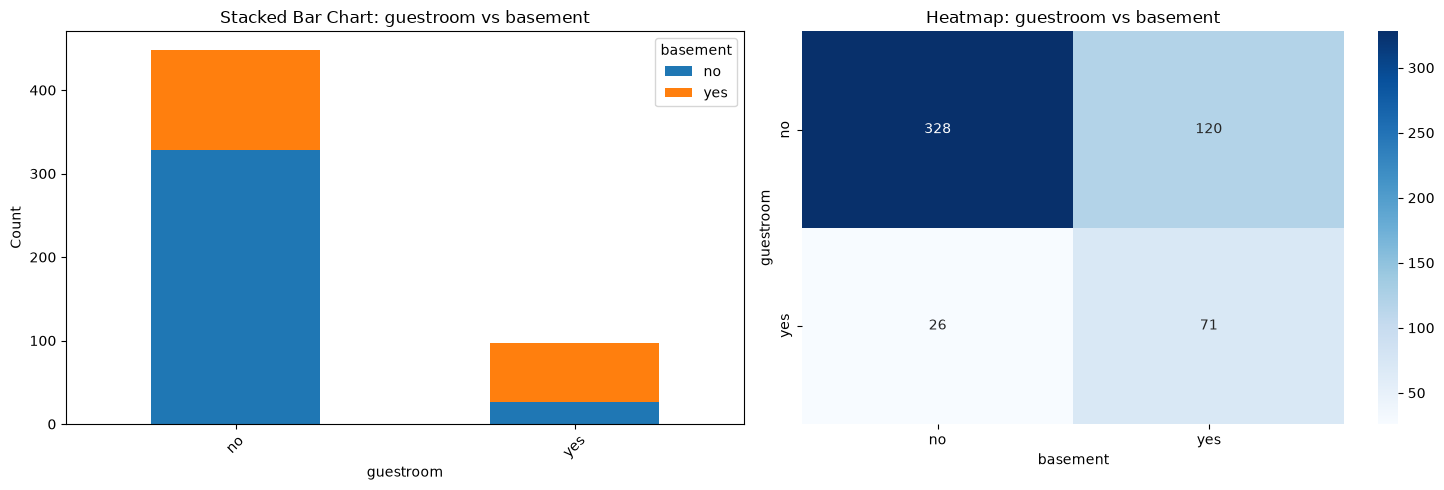


Contingency Table: guestroom vs hotwaterheating
hotwaterheating   no  yes
guestroom                
no               427   21
yes               93    4

Chi-square test:
Chi-square statistic: 0.000
P-value: 1.000
Degrees of freedom: 1


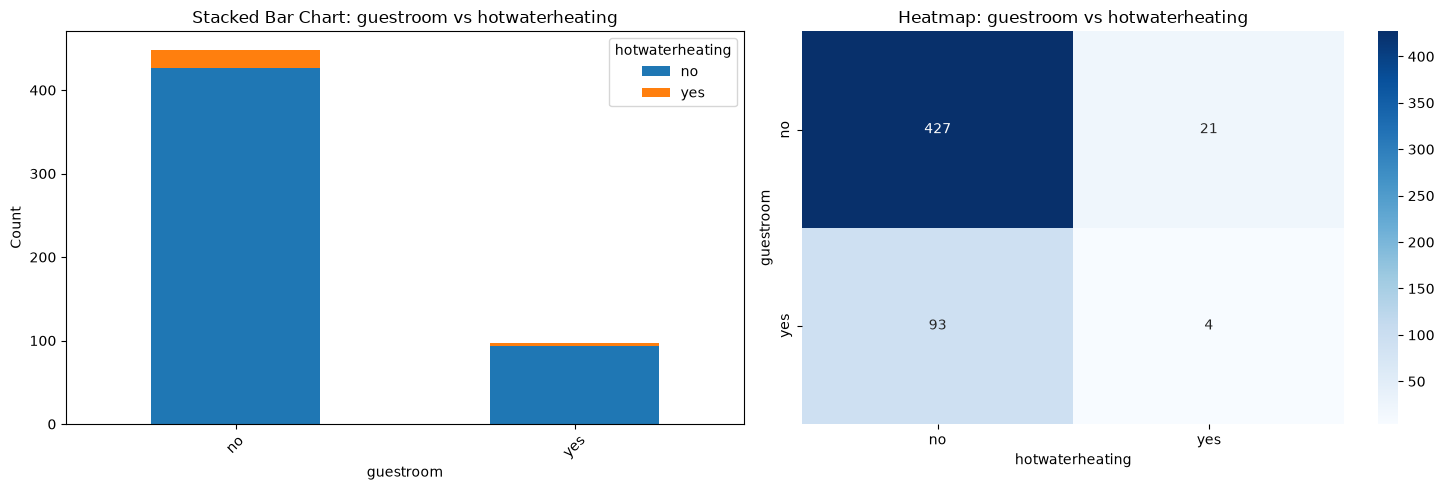


Contingency Table: guestroom vs airconditioning
airconditioning   no  yes
guestroom                
no               320  128
yes               53   44

Chi-square test:
Chi-square statistic: 9.643
P-value: 0.002
Degrees of freedom: 1


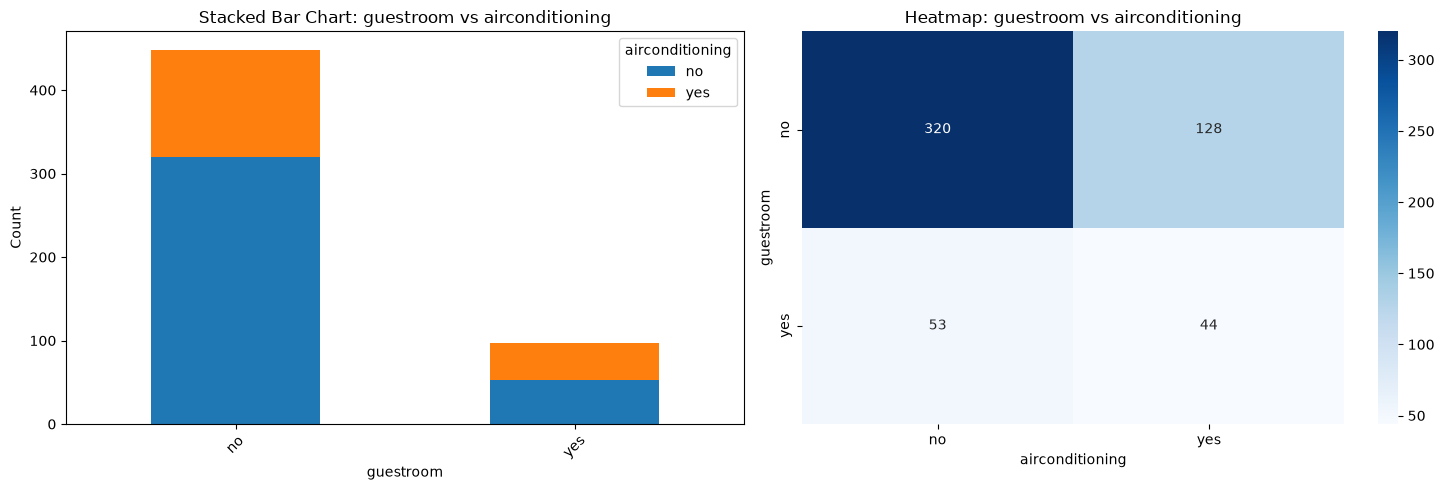


Contingency Table: guestroom vs parking
parking      0   1   2   3
guestroom                 
no         252  99  86  11
yes         47  27  22   1

Chi-square test:
Chi-square statistic: 3.242
P-value: 0.356
Degrees of freedom: 3


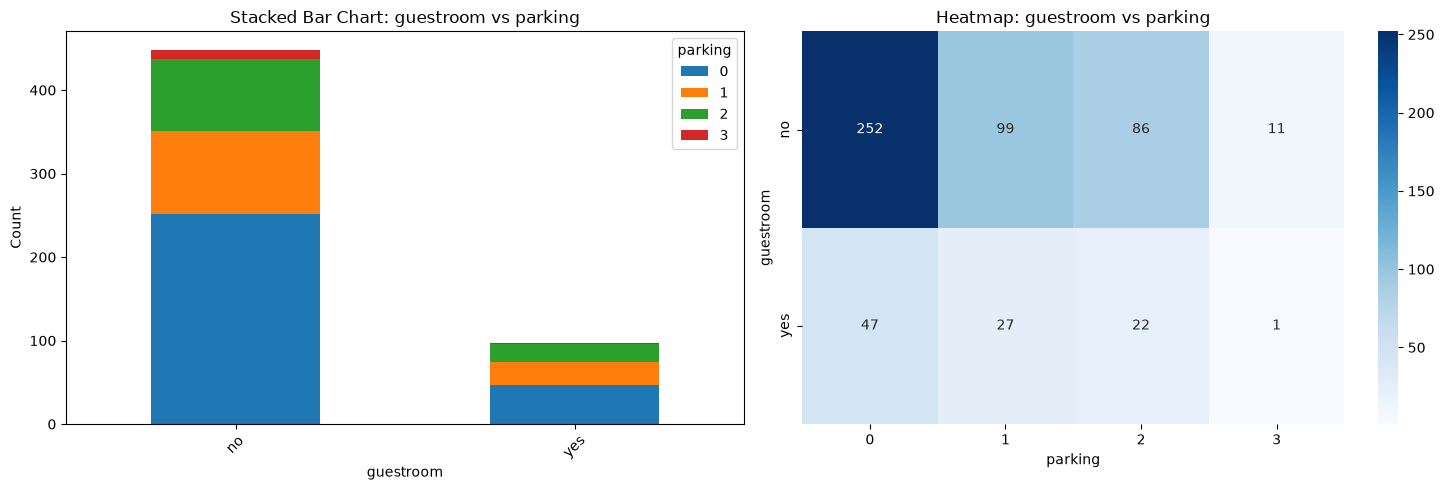


Contingency Table: guestroom vs prefarea
prefarea    no  yes
guestroom          
no         357   91
yes         60   37

Chi-square test:
Chi-square statistic: 13.134
P-value: 0.000
Degrees of freedom: 1


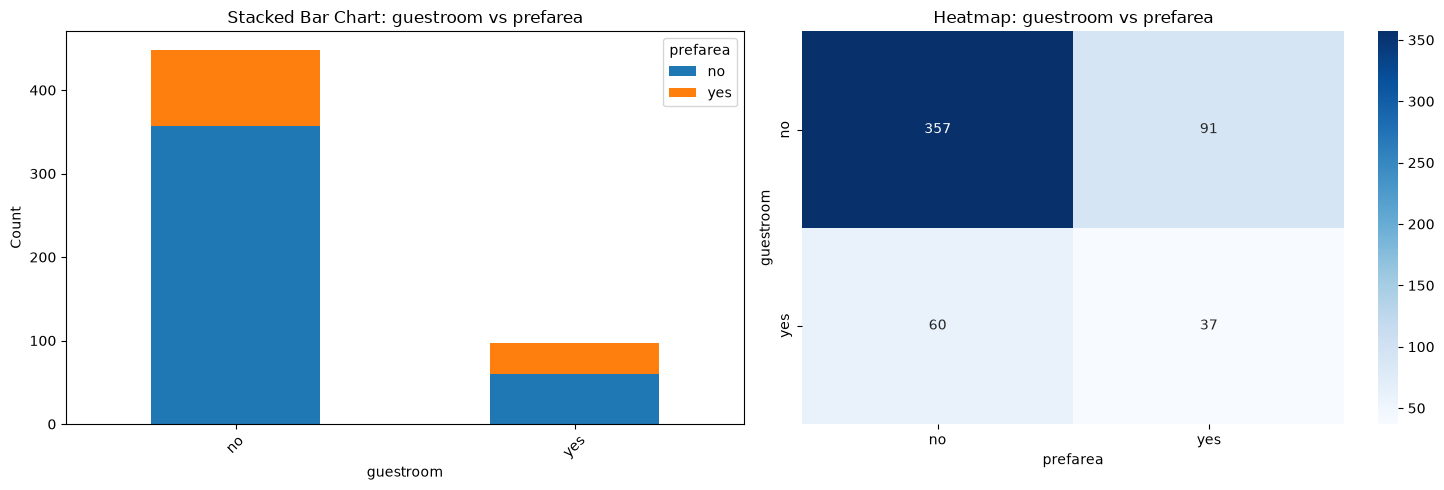


Contingency Table: guestroom vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
guestroom                                               
no                      106             186          156
yes                      34              41           22

Chi-square test:
Chi-square statistic: 7.637
P-value: 0.022
Degrees of freedom: 2


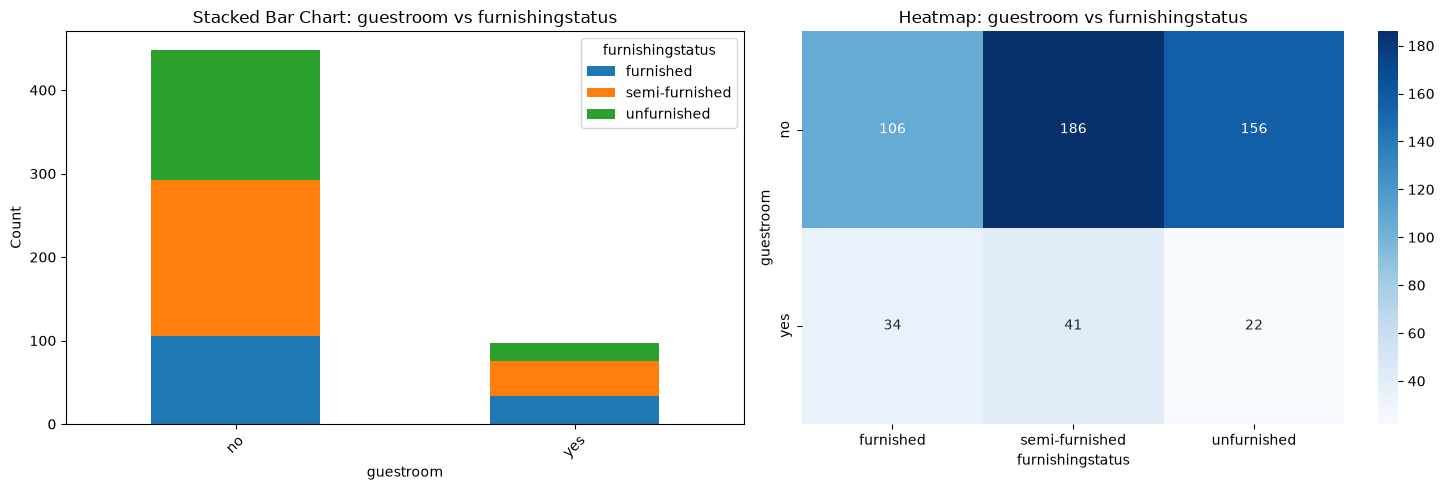


Contingency Table: basement vs hotwaterheating
hotwaterheating   no  yes
basement                 
no               338   16
yes              182    9

Chi-square test:
Chi-square statistic: 0.000
P-value: 1.000
Degrees of freedom: 1


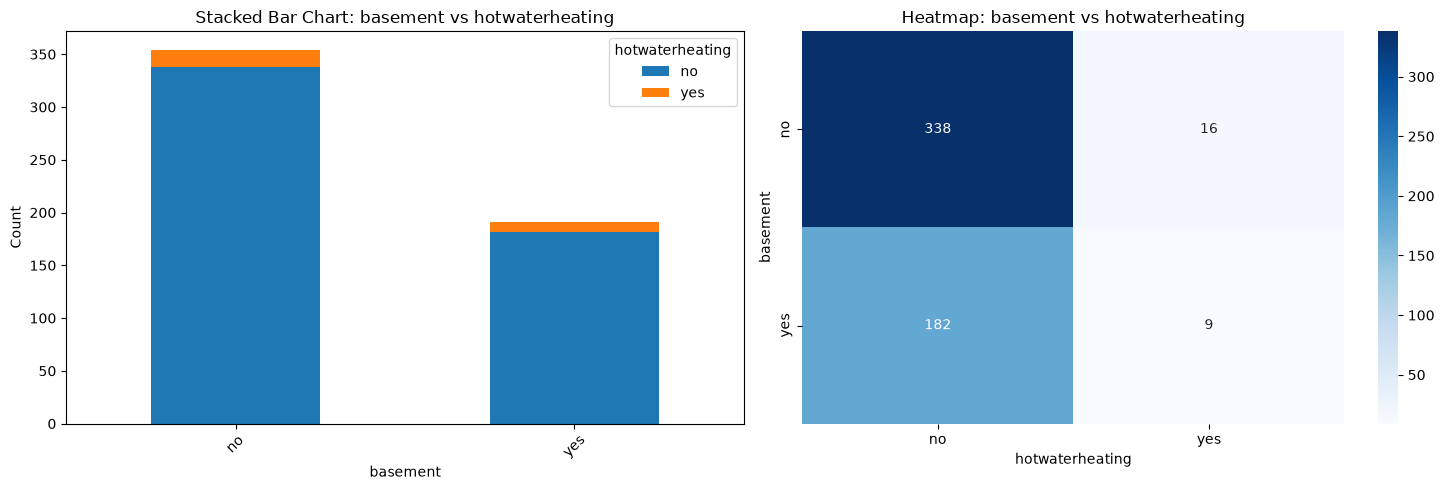


Contingency Table: basement vs airconditioning
airconditioning   no  yes
basement                 
no               248  106
yes              125   66

Chi-square test:
Chi-square statistic: 1.017
P-value: 0.313
Degrees of freedom: 1


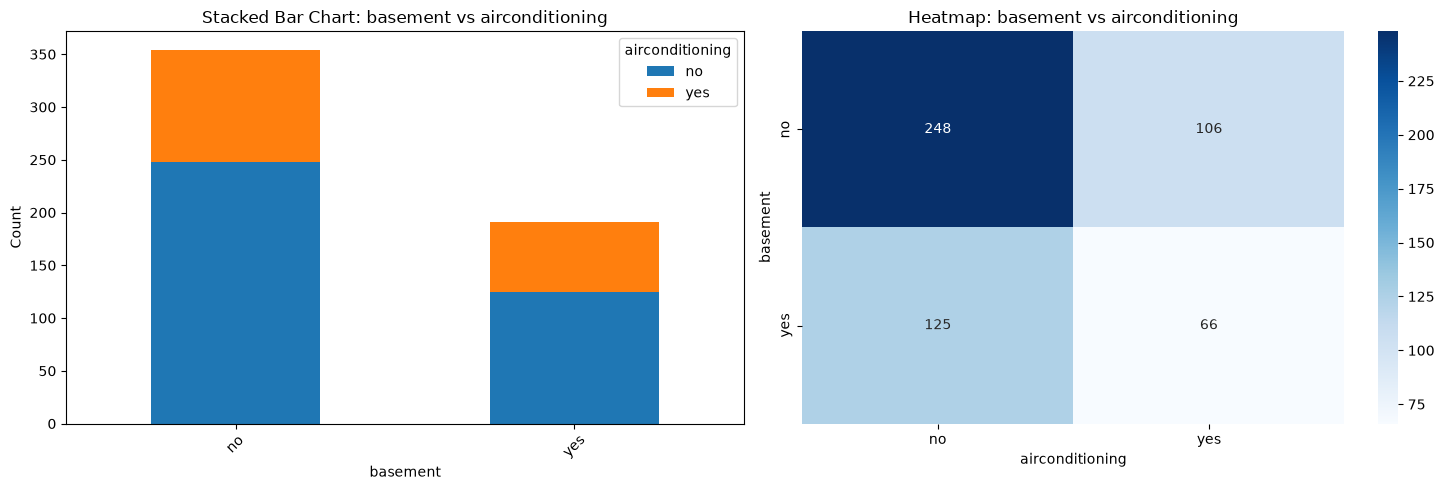


Contingency Table: basement vs parking
parking     0   1   2  3
basement                
no        198  86  62  8
yes       101  40  46  4

Chi-square test:
Chi-square statistic: 3.531
P-value: 0.317
Degrees of freedom: 3


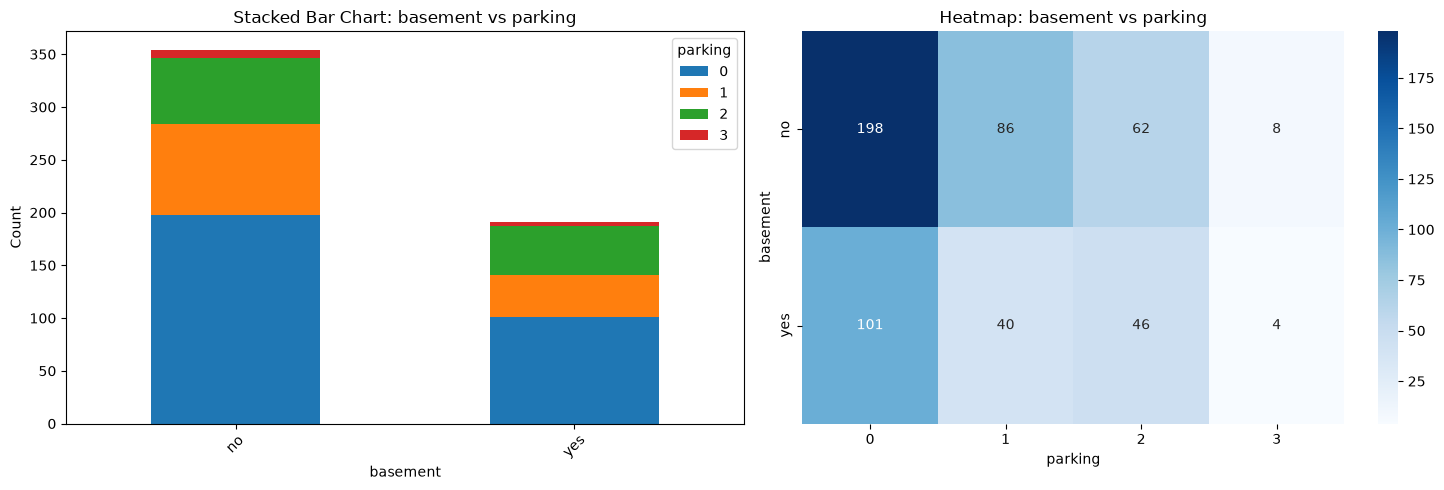


Contingency Table: basement vs prefarea
prefarea   no  yes
basement          
no        296   58
yes       121   70

Chi-square test:
Chi-square statistic: 27.235
P-value: 0.000
Degrees of freedom: 1


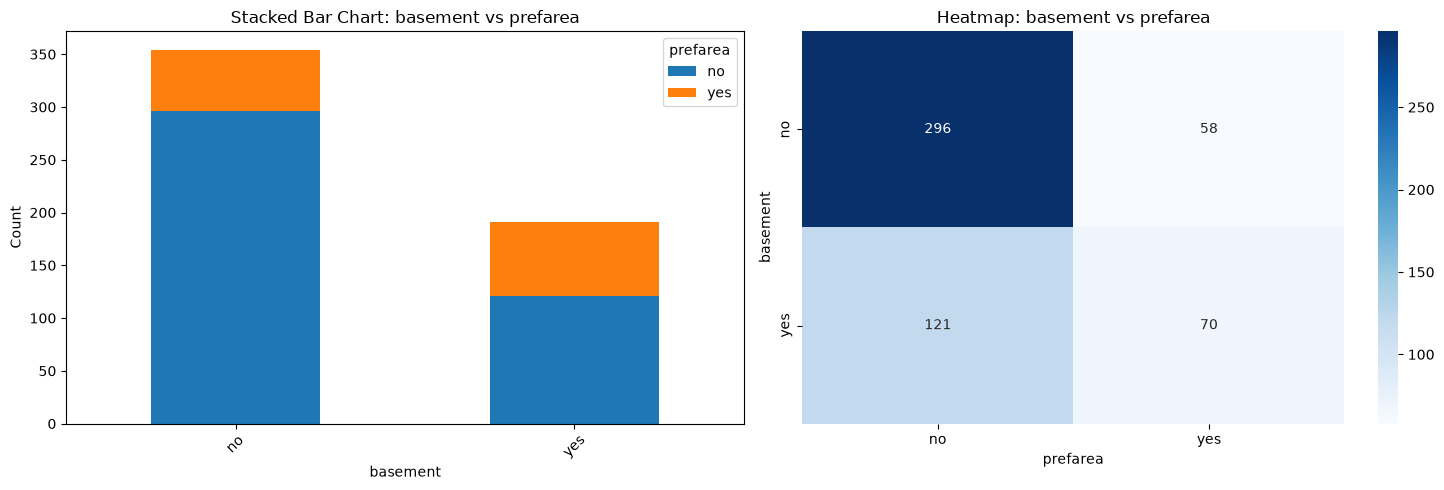


Contingency Table: basement vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
basement                                                
no                       83             141          130
yes                      57              86           48

Chi-square test:
Chi-square statistic: 7.885
P-value: 0.019
Degrees of freedom: 2


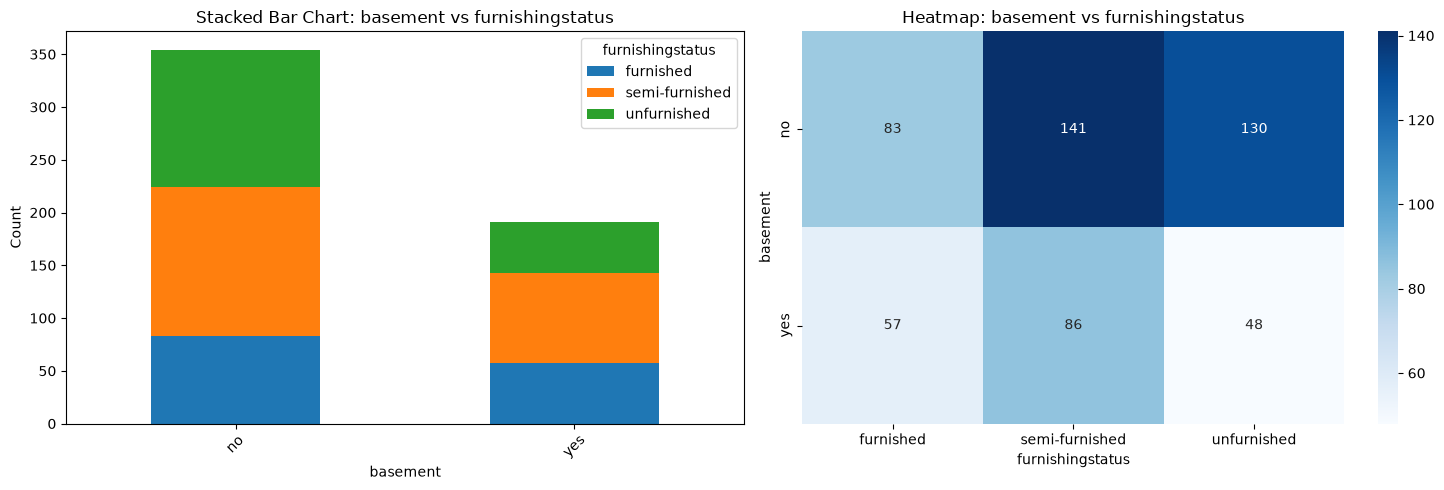


Contingency Table: hotwaterheating vs airconditioning
airconditioning   no  yes
hotwaterheating          
no               349  171
yes               24    1

Chi-square test:
Chi-square statistic: 7.925
P-value: 0.005
Degrees of freedom: 1


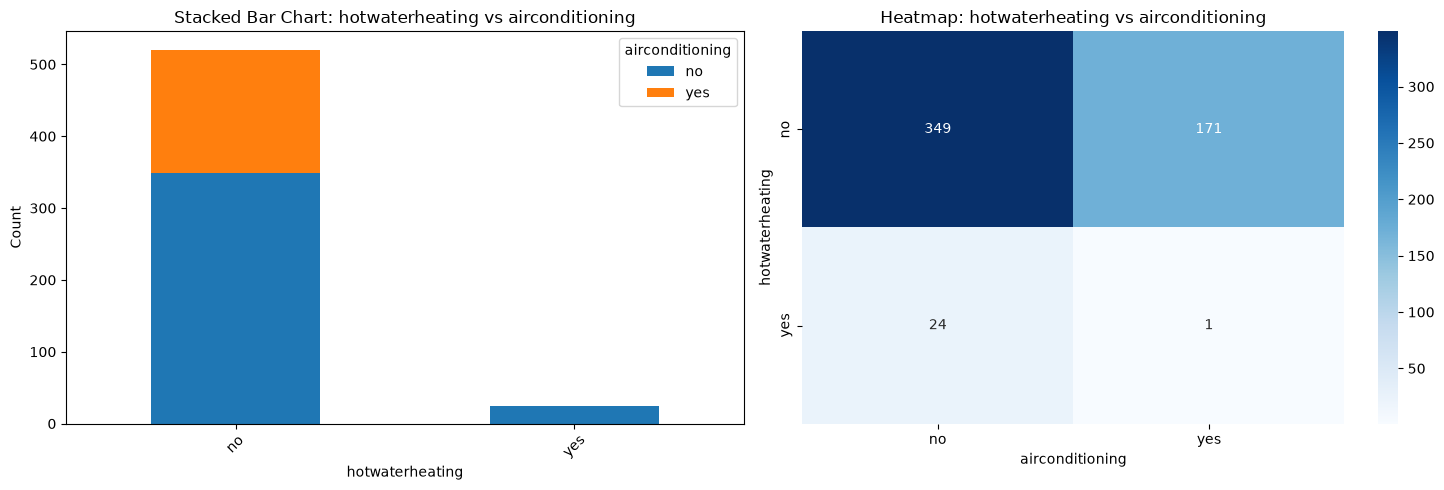


Contingency Table: hotwaterheating vs parking
parking            0    1    2   3
hotwaterheating                   
no               291  116  101  12
yes                8   10    7   0

Chi-square test:
Chi-square statistic: 7.188
P-value: 0.066
Degrees of freedom: 3


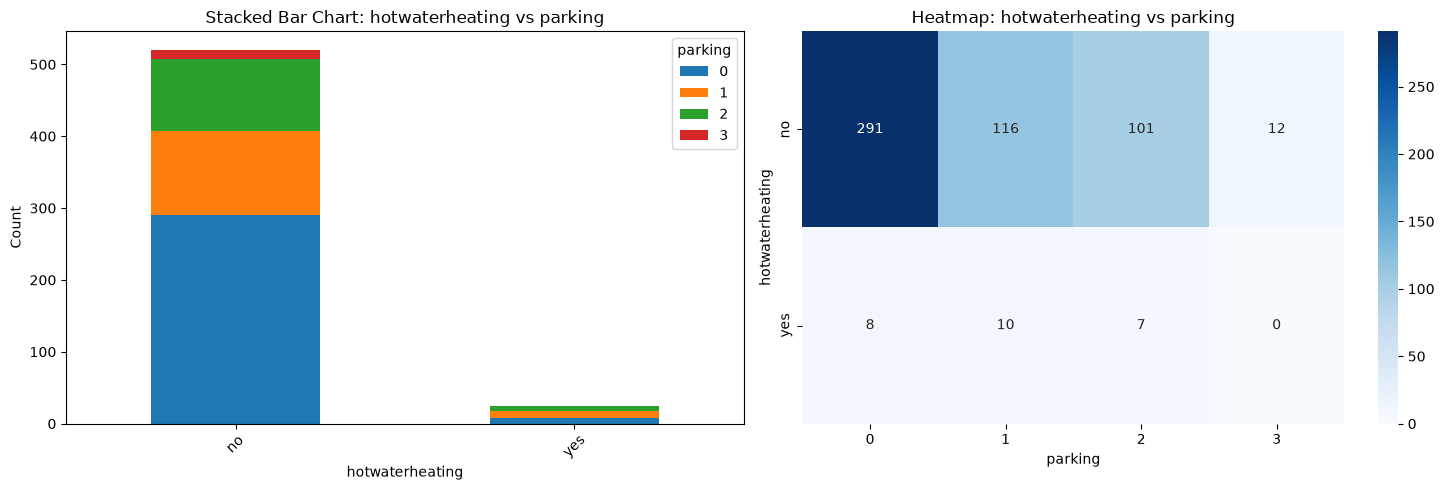


Contingency Table: hotwaterheating vs prefarea
prefarea          no  yes
hotwaterheating          
no               395  125
yes               22    3

Chi-square test:
Chi-square statistic: 1.312
P-value: 0.252
Degrees of freedom: 1


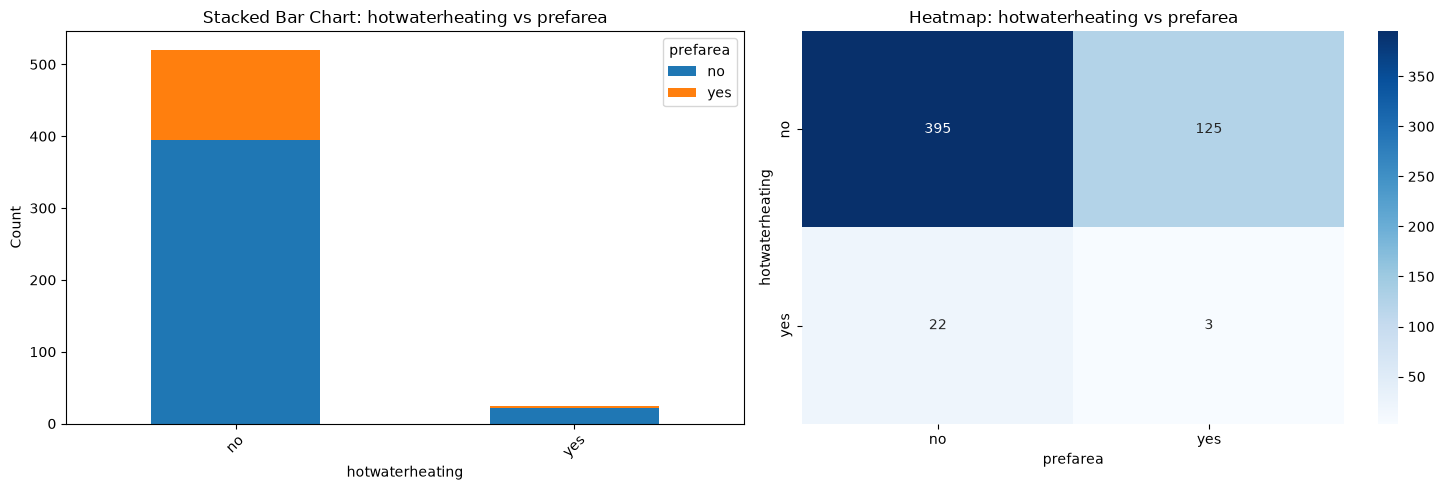


Contingency Table: hotwaterheating vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
hotwaterheating                                         
no                      134             213          173
yes                       6              14            5

Chi-square test:
Chi-square statistic: 2.610
P-value: 0.271
Degrees of freedom: 2


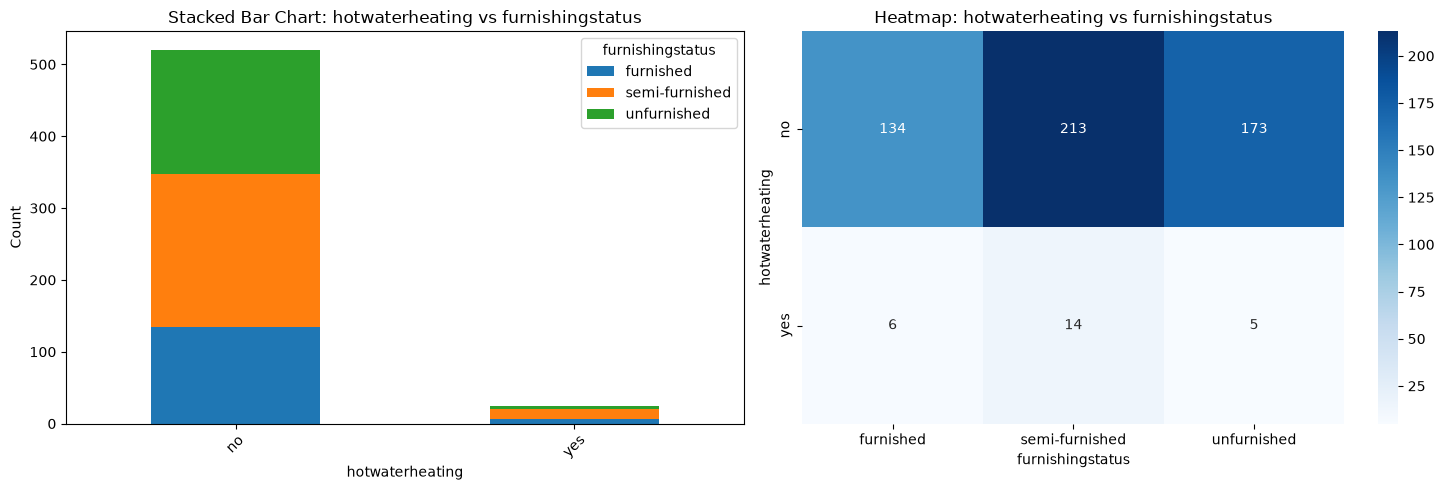


Contingency Table: airconditioning vs parking
parking            0   1   2  3
airconditioning                
no               223  83  60  7
yes               76  43  48  5

Chi-square test:
Chi-square statistic: 14.475
P-value: 0.002
Degrees of freedom: 3


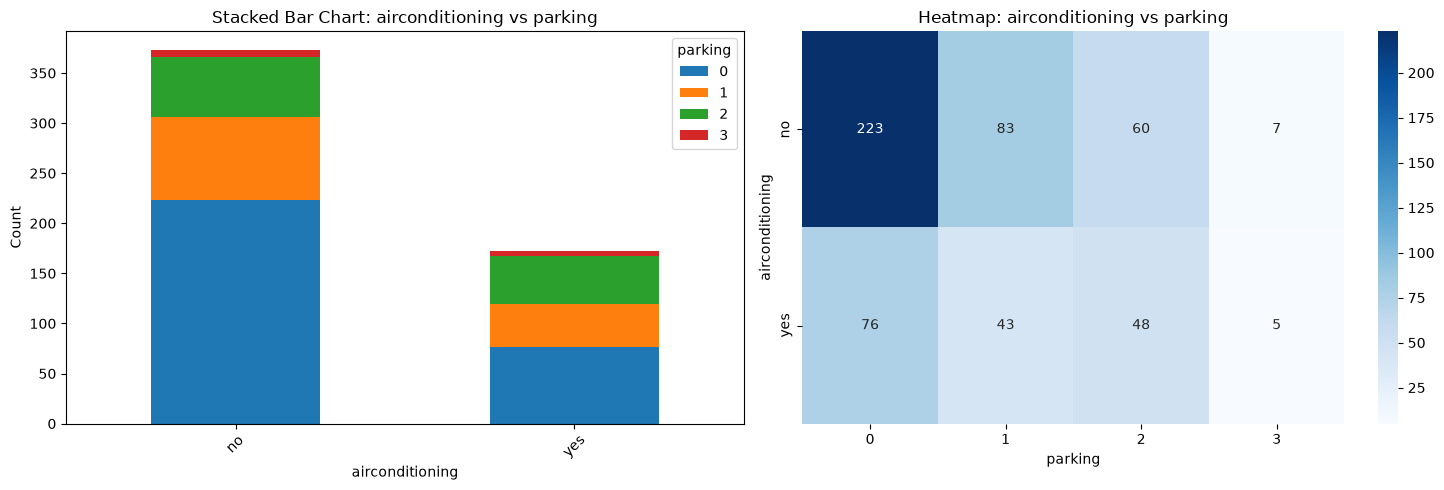


Contingency Table: airconditioning vs prefarea
prefarea          no  yes
airconditioning          
no               298   75
yes              119   53

Chi-square test:
Chi-square statistic: 6.925
P-value: 0.008
Degrees of freedom: 1


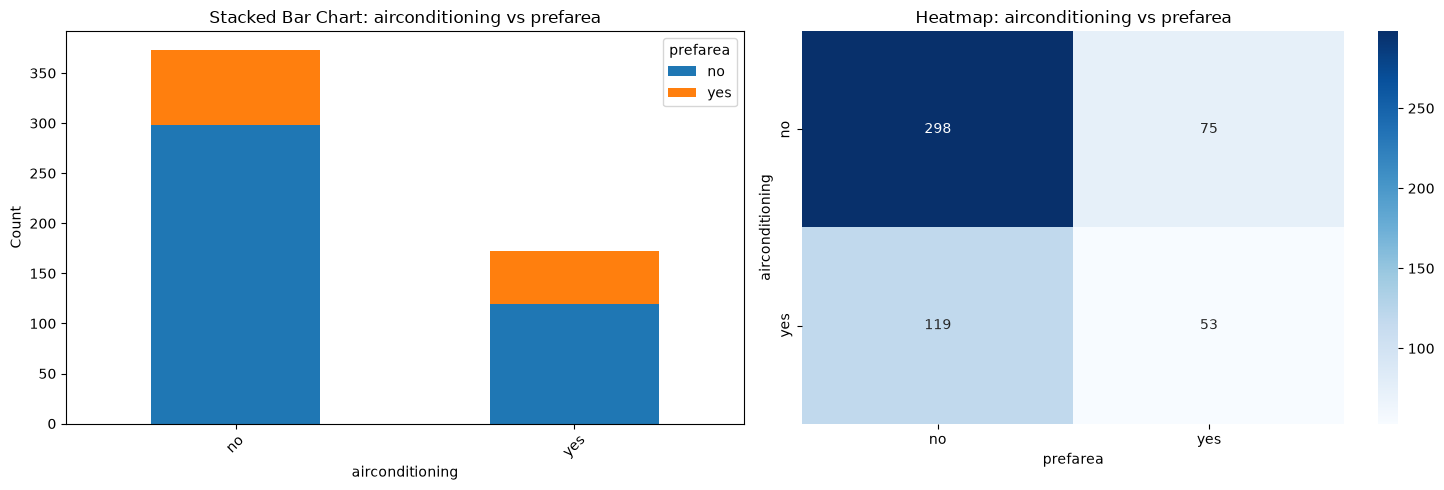


Contingency Table: airconditioning vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
airconditioning                                         
no                       78             162          133
yes                      62              65           45

Chi-square test:
Chi-square statistic: 14.645
P-value: 0.001
Degrees of freedom: 2


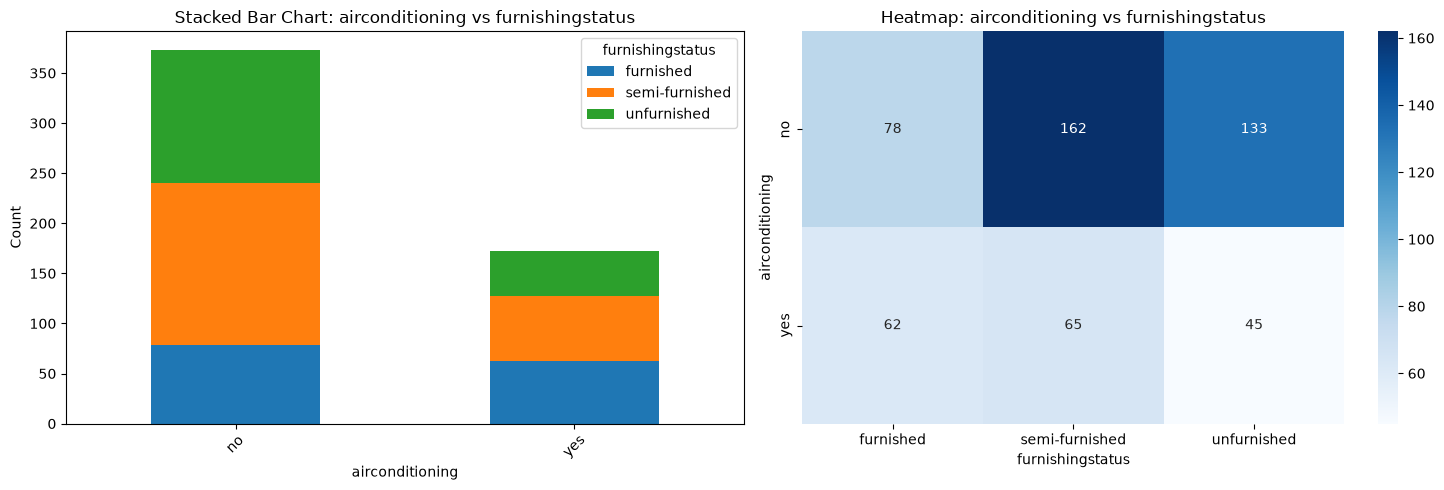


Contingency Table: parking vs prefarea
prefarea   no  yes
parking           
0         237   62
1          98   28
2          73   35
3           9    3

Chi-square test:
Chi-square statistic: 6.169
P-value: 0.104
Degrees of freedom: 3


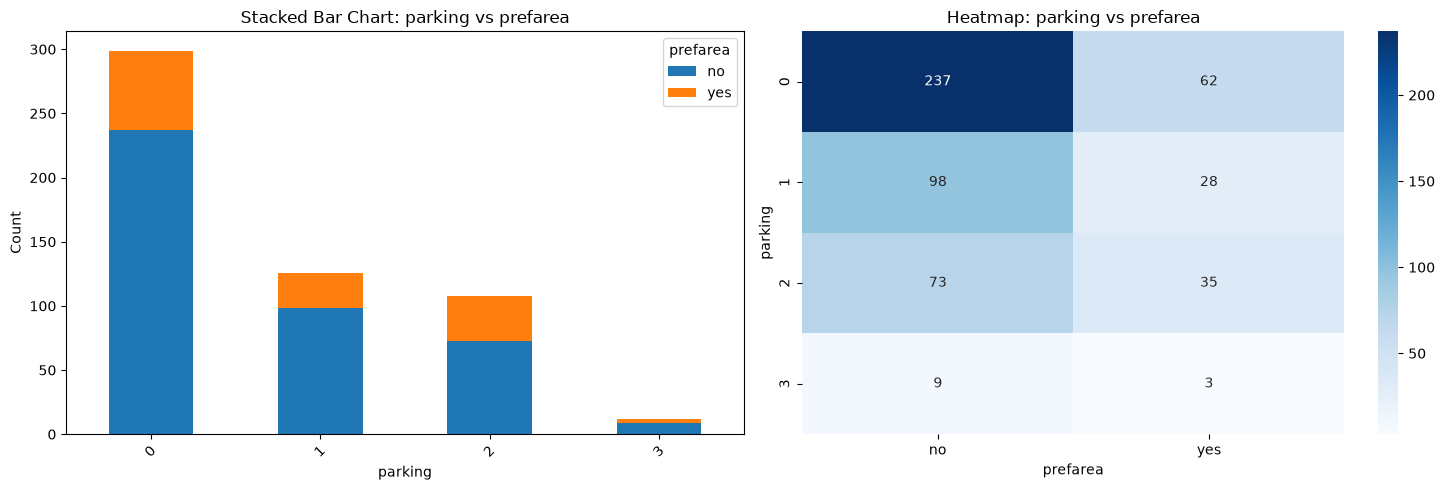


Contingency Table: parking vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
parking                                                 
0                        60             121          118
1                        41              50           35
2                        34              51           23
3                         5               5            2

Chi-square test:
Chi-square statistic: 19.975
P-value: 0.003
Degrees of freedom: 6


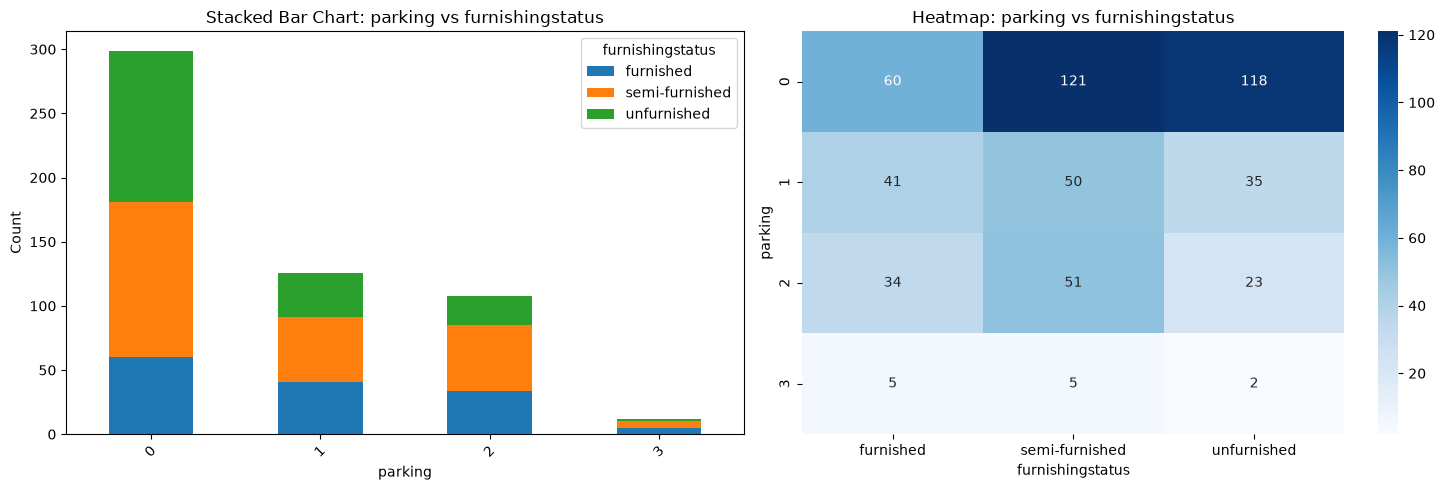


Contingency Table: prefarea vs furnishingstatus
furnishingstatus  furnished  semi-furnished  unfurnished
prefarea                                                
no                       97             175          145
yes                      43              52           33

Chi-square test:
Chi-square statistic: 6.537
P-value: 0.038
Degrees of freedom: 2


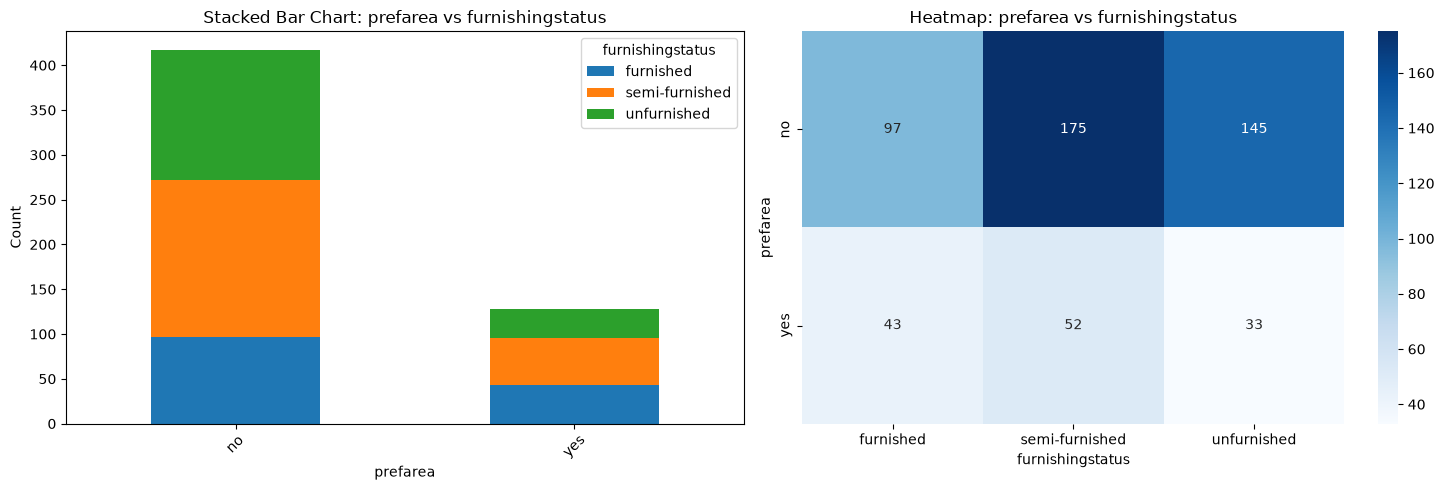

In [39]:
for i in range(len(cat_cols)):
    for j in range(i+1,len(cat_cols)):
        col1=cat_cols[i]
        col2=cat_cols[j]
        analyze_categorical_pair(df,col1,col2)

# Data Preprocessing